# ABNB hotels — NIQ main feed (Order Confirmations)

Goal: track the share of Airbnb bookings that are hotels over time, from NIQ's parse of Airbnb Order Confirmation emails (`accommodation_type`, `hotel_address`; see `R:\Fintan\ABNB\Airbnb E-Receipt Manual.pdf`).

**Phase A (this notebook so far): which NIQ feeds to use.**
1. List every NIQ table we receive (not ones we build).
2. Find which carry Airbnb emails, and how Airbnb shows up in each.
3. Count unique emails per table on one day (`DAY`) to find the master table.
4. Check that IDs carry across tables (exact ID matches only, no fuzzy joins).
5. Show 3 Order Confirmation rows from each feed, linked by ID.

Phase B (layouts by month, `accommodation_type` coverage, samples) follows once the base table and joins are agreed.

Query results are cached under `hotels/.cache/main_feed/` (some queries take 5–15 minutes); delete a file to re-run its query.

In [1]:
import json
from pathlib import Path

import pandas as pd
import snowflake.connector

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)

# Keyring CredWrite fails on this machine (WinError 1783), so don't cache the token.
conn = snowflake.connector.connect(connection_name="default", client_store_temporary_credential=False)

CACHE = Path("hotels/.cache/main_feed") if Path("hotels").is_dir() else Path(".cache/main_feed")
CACHE.mkdir(parents=True, exist_ok=True)


def q(sql: str, name: str | None = None) -> pd.DataFrame:
    """Run sql; if name is given, cache the result as parquet and reuse it."""
    path = CACHE / f"{name}.parquet" if name else None
    if path and path.exists():
        return pd.read_parquet(path)
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    if path:
        df.to_parquet(path)
    return df


DAY = "2025-06-11"  # Wednesday; one day keeps the larger feeds fast
NIQ = "share_niq.srs"

## A1. Which NIQ databases do we receive?

Inbound shares show as `IMPORTED DATABASE`. Our own NIQ-derived builds (`SRS_SLICE.*`, `SRS_FOX`) are `STANDARD` and excluded.

In [2]:
dbs = q("SELECT database_name, database_owner, type, comment, created FROM snowflake.information_schema.databases", "databases")
niq_like = dbs[dbs.database_name.str.contains("NIQ|SLICE|FOX|NIELSEN", regex=True)].sort_values("database_name")
niq_like

,database_name,database_owner,type,comment,created
22,SHARE_FOX_DATA,ACCOUNTADMIN,IMPORTED DATABASE,None,2020-09-16 07:36:57.936000-07:00
19,SHARE_NIQ,ACCOUNTADMIN,IMPORTED DATABASE,NIQ BNPL FEED,2022-05-31 12:34:59.109000-07:00
134,SHARE_SLICE_DATA,ACCOUNTADMIN,IMPORTED DATABASE,None,2020-09-16 07:37:31.637000-07:00
31,SHARE_SLICE_DATA_2,ACCOUNTADMIN,IMPORTED DATABASE,None,2022-06-23 14:42:05.690000-07:00
146,SRS_FOX,SERVICES,STANDARD,None,2020-09-16 07:49:09.819000-07:00
69,SRS_SLICE,SERVICES,STANDARD,None,2020-09-16 07:48:42.732000-07:00


In [3]:
# Which of the inbound ones are still live?
avail = []
for db in niq_like.loc[niq_like.type == "IMPORTED DATABASE", "database_name"]:
    try:
        t = q(f"SELECT table_schema, table_name, table_type, last_altered FROM {db}.information_schema.tables "
              "WHERE table_schema <> 'INFORMATION_SCHEMA'")
        avail.append({"database": db, "status": "live", "tables": len(t)})
    except snowflake.connector.errors.ProgrammingError as e:
        avail.append({"database": db, "status": str(e).split(":")[-1].strip()[:90], "tables": 0})
pd.DataFrame(avail)

,database,status,tables
0,SHARE_FOX_DATA,Shared database is no longer available for use. It will need to be re-created if and when,0
1,SHARE_NIQ,live,67
2,SHARE_SLICE_DATA,live,1
3,SHARE_SLICE_DATA_2,Shared database is no longer available for use. It will need to be re-created if and when,0


## A2. `SHARE_NIQ` inventory

Every view in the share with its columns. `SHARE_SLICE_DATA` holds only `NIQ_REPORT_METRICS_NON_GMAIL` (aggregate metrics), so it isn't listed here.

In [4]:
inv = q("""
    SELECT c.table_schema, c.table_name, t.last_altered::DATE AS last_altered,
           LISTAGG(LOWER(c.column_name), ', ') WITHIN GROUP (ORDER BY c.ordinal_position) AS column_list
    FROM share_niq.information_schema.columns c
    JOIN share_niq.information_schema.tables t USING (table_schema, table_name)
    WHERE c.table_schema <> 'INFORMATION_SCHEMA'
    GROUP BY ALL ORDER BY 1, 2
""", "share_niq_inventory")
inv["has_merchant"] = inv.column_list.str.contains(r"\bmerchant_name\b|\bdomain\b")
inv["has_email_id"] = inv.column_list.str.contains(r"\bmessage_id\b|\bemail_id\b")
inv["has_order_id"] = inv.column_list.str.contains(r"\border_id\b")
with pd.option_context("display.max_colwidth", 400):
    display(inv)

,table_schema,table_name,last_altered,column_list,has_merchant,has_email_id,has_order_id
0,SRS,ACTIVE_PANEL_USERS,2026-05-12,"extract_id, panel_type, active_panel, mailbox_id",False,False,False
1,SRS,AIRLINE_EXTRA,2026-05-12,"extract_id, status, order_id, item_id, merchant_name, airline, cabin_type, flight_number, departure_airport, departure_day, departure_time, departure_city, departure_state, departure_country, arrival_airport, arrival_day, arrival_time, arrival_city, arrival_state, arrival_country, number_stops, last_updated, date_loaded, merchant_ticker, airline_classification, merchant_id, user_id, mailbox_id...",True,False,True
2,SRS,AIRLINE_ITEMS,2026-05-26,"extract_id, order_id, item_id, merchant_name, airline, cabin_type, flight_number, departure_airport, departure_day, departure_time, departure_city, departure_state, departure_country, arrival_airport, arrival_day, arrival_time, arrival_city, arrival_state, arrival_country, number_stops",True,False,True
3,SRS,APPSTORE_HASHES,2026-08-10,"extract_id, order_date, merchant_id, order_id, item_id, description, image_url_http, average_hash, wavelet_hash, perception_hash, difference_hash",False,False,True
4,SRS,BNPL_MERCHANTS,2026-05-27,"extract_id, order_date, merchant_name, new_sellers, cumulative_sellers",True,False,False
5,SRS,BNPL_SELLER_MERCHANT,2026-05-27,"extract_id, merchant_name, payment_merchant_name, order_date, total_revenue, total_orders, total_mailboxes, payment_total_revenue, payment_total_orders, payment_total_mailboxes, payment_merchant_revenue, payment_merchant_count_orders, payment_merchant_count_mailboxes, revenue_pct, count_orders_pct, mailboxes_pct",True,False,False
6,SRS,BNPL_USERS,2026-05-27,"extract_id, order_date, merchant_name, daily_users, annual_active_users, new_users",True,False,False
7,SRS,CANCELLATION_ITEMS,2026-05-25,"extract_id, item_id, order_id, user_id, mailbox_id, merchant_id, merchant_name, description, order_date",True,False,True
8,SRS,CAR_RENTAL_ITEMS,2026-05-25,"extract_id, order_date, merchant_id, merchant_name, item_id, order_id, user_id, mailbox_id, order_total, order_discount, order_subtotal, tax, description, address_in, address_in_airportcode, address_in_city, address_in_state, address_in_country, address_in_zip, address_out, address_out_airportcode, address_out_city, address_out_state, address_out_country, address_out_zip, car_type, car_descrip...",True,False,True
9,SRS,CHWY_AUTOSHIP_ORDERS,2023-03-21,"extract_id, order_date, order_id, subscription",False,False,True


## A3. Which tables carry Airbnb, and how many emails on `DAY`?

Every `SHARE_NIQ` view with a merchant/domain column, filtered to Airbnb on `DAY` (email sent date where the table has one, else `order_date`). Tables without a merchant column (mappings, weights, mailbox lists) are covered by the ID checks in A5.

Not counted, with reason:
- `US_MERCHANT_EMAILS_FLATTEN` / `US_MERCHANT_EMAILS`: the flatten view ran for more than 15 minutes on a single day without finishing. Sample rows carry only `{create_time, order_id}` (see A6).
- `TRANSACTION_EMAIL_DETAILS_UPDATED`: the share returns "Error in secure object" (NIQ-side permission issue).
- `FOX_*`: EU panel, and out of scope (US only).
- `NIQ_GLOBAL_ERECEIPT_*`, `NIQ_GFK_*`, `BNPL_*`, `AIRLINE_*`, `CAR_RENTAL_*` etc.: not Airbnb.

In [5]:
AB = "merchant_name ILIKE '%airbnb%'"
presence_sql = {
    "TRANSACTION_EMAIL_DETAILS": f"""
        SELECT merchant_name, email_attributes:reservation:email_type::STRING AS email_type,
               email_attributes:reservation:order_status::STRING AS order_status,
               COUNT(*) AS n_rows, COUNT(DISTINCT message_id) AS n_email_ids, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.transaction_email_details WHERE email_sent_time::DATE = '{DAY}' AND {AB} GROUP BY ALL""",
    "EMAIL_HEADER": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT message_id) AS n_email_ids, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.email_header WHERE email_sent_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "EMAIL_HEADER_FTA": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT message_id) AS n_email_ids
        FROM {NIQ}.email_header_fta WHERE email_sent_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "ITEMS_EXTENDED": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.items_extended WHERE email_sent_time::DATE = '{DAY}' AND {AB} GROUP BY ALL""",
    "FINANCIAL_TRANSACTIONS_ATTRIBUTES": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.financial_transactions_attributes WHERE email_sent_time::DATE = '{DAY}' AND {AB} GROUP BY ALL""",
    "ITEMS_CLASSIFICATION": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.items_classification WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "CANCELLATION_ITEMS": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.cancellation_items WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "HOTELS_OTA_PLATFORM": f"""
        SELECT merchant_name, COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_order_ids
        FROM {NIQ}.hotels_ota_platform WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "ORDER_NUMBERS": f"""
        SELECT merchant_name, COUNT(*) AS n_rows
        FROM {NIQ}.order_numbers WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "ORDER_TOTAL_ONLY_MERCHANTS": f"""
        SELECT merchant_name, COUNT(*) AS n_rows FROM {NIQ}.order_total_only_merchants WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "PAYMENT_MERCHANTS_SELLER_NAMES": f"""
        SELECT merchant_name, COUNT(*) AS n_rows FROM {NIQ}.payment_merchants_seller_names WHERE order_date = '{DAY}' AND {AB} GROUP BY ALL""",
    "SUPRA_QUALITY_MERCHANT_EMAILS": f"""
        SELECT 'domain=airbnb' AS merchant_name, e.email_type, COUNT(*) AS n_rows, COUNT(DISTINCT e.email_id) AS n_email_ids
        FROM {NIQ}.supra_quality_merchant_emails e JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
        WHERE e.email_sent_date = '{DAY}' AND h.domain = 'airbnb' GROUP BY ALL""",
    "SUPRA_NON_QUALITY_MERCHANT_EMAILS": f"""
        SELECT 'domain~airbnb' AS merchant_name, e.email_type, COUNT(*) AS n_rows, COUNT(DISTINCT e.email_id) AS n_email_ids
        FROM {NIQ}.supra_non_quality_merchant_emails e JOIN {NIQ}.supra_non_quality_merchant_email_header h ON e.subject_id = h.subject_id
        WHERE e.email_sent_date = '{DAY}' AND h.domain ILIKE '%airbnb%' GROUP BY ALL""",
}
# HOTEL_ITEMS has no email/order date; it is linked by order_id in A5.

presence = pd.concat(
    [q(sql, f"presence_{t.lower()}").assign(table=t) for t, sql in presence_sql.items()], ignore_index=True)
cols = ["table", "merchant_name", "email_type", "order_status", "n_rows", "n_email_ids", "n_order_ids"]
presence = presence[cols]
presence

,table,merchant_name,email_type,order_status,n_rows,n_email_ids,n_order_ids
0,TRANSACTION_EMAIL_DETAILS,AirBnB Receipts,receipt,updated,223,223.0,0.0
1,TRANSACTION_EMAIL_DETAILS,AirBnB Receipts Cancellation,receipt,canceled,248,248.0,0.0
2,TRANSACTION_EMAIL_DETAILS,AirBnB Receipts,receipt,confirmed,1820,1820.0,0.0
3,TRANSACTION_EMAIL_DETAILS,AirBnB Cancellation,confirmation,canceled,297,297.0,0.0
4,TRANSACTION_EMAIL_DETAILS,AirBnB,confirmation,confirmed,1504,1504.0,0.0
5,EMAIL_HEADER,AirBnB,NaN,NaN,1362,1362.0,1362.0
6,EMAIL_HEADER,AirBnB Receipts Cancellation,NaN,NaN,219,219.0,215.0
7,EMAIL_HEADER,AirBnB Cancellation,NaN,NaN,271,271.0,271.0
8,EMAIL_HEADER,AirBnB Receipts,NaN,NaN,1656,1656.0,1654.0
9,ITEMS_EXTENDED,AirBnB,NaN,NaN,1361,NaN,1361.0


In [6]:
# Tables with no Airbnb rows on DAY
[t for t in presence_sql if t not in set(presence.table)]

['EMAIL_HEADER_FTA',
 'FINANCIAL_TRANSACTIONS_ATTRIBUTES',
 'ORDER_TOTAL_ONLY_MERCHANTS',
 'PAYMENT_MERCHANTS_SELLER_NAMES',
 'SUPRA_NON_QUALITY_MERCHANT_EMAILS']

## A4. NIQ's own log of Airbnb template changes

`MERCHANTS_WITH_ISSUES` is NIQ's changelog of parsing breaks and template fixes. It's the best guide to when layouts change, so we use it to annotate the Phase B monthly layout counts.

In [7]:
mwi = q(f"SELECT merchant_id, merchant_name, first_reported_date, updated_date, status, known_issues, note "
        f"FROM {NIQ}.merchants_with_issues WHERE {AB} ORDER BY first_reported_date", "merchants_with_issues")
with pd.option_context("display.max_colwidth", 600):
    display(mwi)

,merchant_id,merchant_name,first_reported_date,updated_date,status,known_issues,note
0,1501,AirBnB,2023-05-31,2023-06-19,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
1,1501,AirBnB,2023-06-09,2023-06-19,Fixed,Issue was found on merchant AirBnB since 6/6/2023,"[AirBnb] had made the COMPLEX structural change to emails starting 6/6/2023 which resulted in parsing issue and data decline observed earlier. We are now capturing this new email template and as of 6/19/2023, we have backfilled all of the missing data so everything should be looking normal now."
2,3487,AirBnB Cancellation,2023-06-27,2023-07-10,Fixed,Receipt layout change,
3,1501,AirBnB,2023-07-05,2023-07-05,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."
4,3487,AirBnB Cancellation,2023-07-07,2023-07-10,Fixed,Issue was found on merchant AirBnB Cancellation since 6/27/2023,"[Airbnb Cancellations] had made minor structural changes to emails starting 6/28/2023 which resulted in parsing issues and data decline observed earlier.We are now capturing this new email template and as of 7/10/2023, we have backfilled all of the missing data so everything should be looking normal now."
5,1501,AirBnB,2023-07-16,2023-08-03,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
6,3487,AirBnB Cancellation,2023-07-23,2023-08-04,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
7,3487,AirBnB Cancellation,2023-09-17,2023-09-27,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
8,3487,AirBnB Cancellation,2023-09-28,2023-09-28,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."
9,1501,AirBnB,2023-12-24,2023-12-24,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."


## A5. Do the IDs carry across tables?

Base: every Airbnb email in `TRANSACTION_EMAIL_DETAILS` (TED) sent on `DAY`. For each, check whether its ID appears in the other feeds:

- `message_id` → `EMAIL_HEADER.message_id`, `ORDER_ID_MESSAGE_ID_MAPPING.message_id`, `SUPRA_QUALITY_MERCHANT_EMAILS.email_id`
- the `order_id` from the mapping → `ITEMS_EXTENDED`, `ITEMS_CLASSIFICATION`, `HOTEL_ITEMS`, `HOTELS_OTA_PLATFORM`, `CANCELLATION_ITEMS`

TED's own `order_id` is NULL for every Airbnb row (A3), so the order tables can only be reached through the mapping.

In [8]:
links = q(f"""
    WITH ted AS (SELECT DISTINCT merchant_name, message_id FROM {NIQ}.transaction_email_details
                 WHERE email_sent_time::DATE = '{DAY}' AND {AB}),
    m AS (SELECT DISTINCT message_id, order_id FROM {NIQ}.order_id_message_id_mapping
          WHERE message_id IN (SELECT message_id FROM ted)),
    tm AS (SELECT ted.merchant_name, ted.message_id, m.order_id FROM ted LEFT JOIN m USING (message_id))
    SELECT merchant_name,
      COUNT(DISTINCT message_id) AS ted_emails,
      COUNT(DISTINCT IFF(message_id IN (SELECT message_id FROM {NIQ}.email_header
            WHERE email_sent_date BETWEEN DATEADD(day, -7, '{DAY}') AND DATEADD(day, 7, '{DAY}') AND {AB}), message_id, NULL)) AS in_email_header,
      COUNT(DISTINCT IFF(message_id IN (SELECT email_id FROM {NIQ}.supra_quality_merchant_emails
            WHERE email_sent_date BETWEEN DATEADD(day, -1, '{DAY}') AND DATEADD(day, 1, '{DAY}')), message_id, NULL)) AS in_supra,
      COUNT(DISTINCT IFF(order_id IS NOT NULL, message_id, NULL)) AS in_order_map,
      COUNT(DISTINCT order_id) AS mapped_order_ids,
      COUNT(DISTINCT IFF(order_id IN (SELECT order_id FROM {NIQ}.items_extended WHERE {AB} AND email_sent_time >= DATEADD(day, -40, '{DAY}')), order_id, NULL)) AS in_items_extended,
      COUNT(DISTINCT IFF(order_id IN (SELECT order_id FROM {NIQ}.items_classification WHERE {AB} AND order_date >= DATEADD(day, -40, '{DAY}')), order_id, NULL)) AS in_items_classification,
      COUNT(DISTINCT IFF(order_id IN (SELECT order_id FROM {NIQ}.hotel_items WHERE {AB}), order_id, NULL)) AS in_hotel_items,
      COUNT(DISTINCT IFF(order_id IN (SELECT order_id FROM {NIQ}.hotels_ota_platform WHERE {AB} AND order_date >= DATEADD(day, -40, '{DAY}')), order_id, NULL)) AS in_hotels_ota,
      COUNT(DISTINCT IFF(order_id IN (SELECT order_id FROM {NIQ}.cancellation_items WHERE {AB} AND order_date >= DATEADD(day, -40, '{DAY}')), order_id, NULL)) AS in_cancellation_items
    FROM tm GROUP BY 1 ORDER BY 2 DESC
""", "links")
links

,merchant_name,ted_emails,in_email_header,in_supra,in_order_map,mapped_order_ids,in_items_extended,in_items_classification,in_hotel_items,in_hotels_ota,in_cancellation_items
0,AirBnB Receipts,2043,1613,1858,1613,1611,1480,1610,1611,0,0
1,AirBnB,1504,1320,1362,1320,1320,1319,1319,1320,48,0
2,AirBnB Cancellation,297,268,278,0,0,0,0,0,0,0
3,AirBnB Receipts Cancellation,248,219,225,0,0,0,0,0,0,0


### Is TED missing emails that Supra has?

Supra covers every email from the airbnb.com domain, receipts or not, so it's the widest net. Group the day's Supra Airbnb emails (excluding `NOT_A_RECEIPT`) by subject prefix and sender, and flag which are in TED (on `email_id` = `message_id`, sent `DAY`±1).

In [9]:
supra_vs_ted = q(f"""
    WITH ted AS (SELECT DISTINCT message_id, merchant_name FROM {NIQ}.transaction_email_details
                 WHERE email_sent_time::DATE BETWEEN DATEADD(day, -1, '{DAY}') AND DATEADD(day, 1, '{DAY}') AND {AB}),
    s AS (SELECT e.email_id, e.email_type, h.subject, h.from_addr,
                 e.aux_data:merchant_details:merchant_name::STRING AS supra_merchant
          FROM {NIQ}.supra_quality_merchant_emails e JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
          WHERE e.email_sent_date = '{DAY}' AND h.domain = 'airbnb' AND e.email_type <> 'NOT_A_RECEIPT')
    SELECT REGEXP_SUBSTR(s.subject, '^[^0-9_–-]{{0,40}}') AS subject_prefix, s.from_addr, s.email_type, s.supra_merchant,
           ted.merchant_name AS ted_merchant, COUNT(*) AS n
    FROM s LEFT JOIN ted ON s.email_id = ted.message_id
    GROUP BY ALL HAVING n >= 15 ORDER BY n DESC
""", "supra_vs_ted")
supra_vs_ted

,subject_prefix,from_addr,email_type,supra_merchant,ted_merchant,n
0,Reservation reminder:,automated@airbnb.com,SHIPPING,AirBnB,None,2048
1,Your receipt from Airbnb,automated@airbnb.com,ORDER,AirBnB Receipts,AirBnB Receipts,1858
2,Reservation confirmed,automated@airbnb.com,ORDER,AirBnB,None,1361
3,Welcome to,automated@airbnb.com,WELCOME,None,None,695
4,Confirmed: Your reservation for,automated@airbnb.com,ORDER,AirBnB,AirBnB,532
5,A $,express@airbnb.com,PAYMENT,None,None,496
6,Your refund is on its way,automated@airbnb.com,RETURNS,AirBnB Cancellation,None,469
7,Your payment is coming up,automated@airbnb.com,PAYMENT,None,None,435
8,Protect your trip with travel insurance,discover@airbnb.com,ORDER,None,None,425
9,Confirmed: Your reservation for Jul,automated@airbnb.com,ORDER,AirBnB,AirBnB,389


## A6. Sample Order Confirmations, linked across feeds

Three TED Order Confirmations (merchant `AirBnB`) from `DAY` that have a mapped `order_id`, picked by hash for repeatability, with the matching rows from every linked feed.

In [10]:
oc = q(f"""
    SELECT t.message_id, m.order_id, t.mailbox_id, t.merchant_name, t.email_sent_time, t.email_attributes
    FROM {NIQ}.transaction_email_details t
    JOIN {NIQ}.order_id_message_id_mapping m ON t.message_id = m.message_id
    WHERE t.email_sent_time::DATE = '{DAY}' AND t.merchant_name = 'AirBnB'
    ORDER BY HASH(t.message_id) LIMIT 3
""", "sample_ted")
msg_ids = ", ".join(f"'{m}'" for m in oc.message_id)
ord_ids = ", ".join(f"'{o}'" for o in oc.order_id)
for r in oc.itertuples():
    print(f"--- TED message_id={r.message_id}  order_id={r.order_id}  sent={r.email_sent_time}")
    print(json.dumps(json.loads(r.email_attributes), indent=1)[:4000])

--- TED message_id=4f02a839-00a6-37eb-b980-8d734af72a16  order_id=a16c3814-2144-3668-b40d-1c3927ad98cd  sent=2025-06-11 18:32:24
{
 "reservation": {
  "accommodation_type": "Entire home/apt",
  "checkin_date": "Jun 19",
  "checkin_time_details": "After 3:00\u202fPM",
  "checkout_date": "Jun 21",
  "checkout_time_details": "By 11:00\u202fAM",
  "email_currency": "USD",
  "email_type": "confirmation",
  "hotel_address": {
   "city": "",
   "country": "ISRAEL",
   "state": "",
   "zip": ""
  },
  "hotel_name": "Luxury __ __ __ in __",
  "order_status": "confirmed",
  "payment_details": [
   {
    "payment_amount": "$3,165.06",
    "payment_date": "Jun 11, 2025 12:32 PM CST",
    "payment_method": "__"
   }
  ],
  "reservation_number": "P0fJYGO3gAGiGlFEvV8d",
  "total_paid": "$3,165.06",
  "travelers_details": "15 adults"
 }
}
--- TED message_id=a768bde5-13d7-375b-b2f5-0efe72faf3ec  order_id=4ded4e34-840b-31e3-8ac4-d78fb533248b  sent=2025-06-11 19:40:36
{
 "reservation": {
  "accommodation

In [11]:
linked = {
    "EMAIL_HEADER": f"SELECT * FROM {NIQ}.email_header WHERE message_id IN ({msg_ids}) AND email_sent_date BETWEEN DATEADD(day, -7, '{DAY}') AND DATEADD(day, 7, '{DAY}')",
    "ORDER_ID_MESSAGE_ID_MAPPING": f"SELECT * FROM {NIQ}.order_id_message_id_mapping WHERE message_id IN ({msg_ids})",
    "SUPRA_QUALITY_MERCHANT_EMAILS + HEADER": f"""
        SELECT e.*, h.subject, h.from_addr, h.aux_data AS header_aux_data
        FROM {NIQ}.supra_quality_merchant_emails e JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
        WHERE e.email_id IN ({msg_ids}) AND e.email_sent_date BETWEEN DATEADD(day, -1, '{DAY}') AND DATEADD(day, 1, '{DAY}')""",
    "ITEMS_EXTENDED": f"SELECT * FROM {NIQ}.items_extended WHERE order_id IN ({ord_ids})",
    "ITEMS_CLASSIFICATION": f"SELECT * FROM {NIQ}.items_classification WHERE order_id IN ({ord_ids})",
    "HOTEL_ITEMS": f"SELECT * FROM {NIQ}.hotel_items WHERE order_id IN ({ord_ids})",
    "HOTELS_OTA_PLATFORM": f"SELECT * FROM {NIQ}.hotels_ota_platform WHERE order_id IN ({ord_ids})",
    "CANCELLATION_ITEMS": f"SELECT * FROM {NIQ}.cancellation_items WHERE order_id IN ({ord_ids})",
}
for t, sql in linked.items():
    df = q(sql, f"sample_{t.split()[0].lower()}")
    print(f"\n=== {t}: {len(df)} rows")
    display(df.T if len(df) else df)


=== EMAIL_HEADER: 3 rows


,0,1,2
extract_id,182981,182981,182981
message_order_id,17ee0434-9014-598c-db4c-5beedf524b7d,98df44c3-2c3d-7bf1-71ab-77808127a0e5,3e2552ee-c54a-a5c2-4439-985ac5f2ef72
message_id,a768bde5-13d7-375b-b2f5-0efe72faf3ec,4f02a839-00a6-37eb-b980-8d734af72a16,6774d2dd-27c3-36b7-a26a-775bd28bdd14
order_id,4ded4e34-840b-31e3-8ac4-d78fb533248b,a16c3814-2144-3668-b40d-1c3927ad98cd,4f8f05aa-8b5e-3af6-a508-c370aa5ed583
merchant_id,1501,1501,1501
merchant_name,AirBnB,AirBnB,AirBnB
order_date,2025-06-11,2025-06-11,2025-06-11
email_sent_date,2025-06-11,2025-06-11,2025-06-11
sequence,1,1,1
subject,"Confirmed: Your reservation for Dec 29, 2025 – __ 2, 2026",Confirmed: Your reservation for __ 19 – 21,Confirmed: Your reservation for Jun 11 – 13



=== ORDER_ID_MESSAGE_ID_MAPPING: 3 rows


,0,1,2
extract_id,178817,178817,178817
order_id,a16c3814-2144-3668-b40d-1c3927ad98cd,4ded4e34-840b-31e3-8ac4-d78fb533248b,4f8f05aa-8b5e-3af6-a508-c370aa5ed583
message_id,4f02a839-00a6-37eb-b980-8d734af72a16,a768bde5-13d7-375b-b2f5-0efe72faf3ec,6774d2dd-27c3-36b7-a26a-775bd28bdd14
status,I,I,I



=== SUPRA_QUALITY_MERCHANT_EMAILS + HEADER: 3 rows


...

,0,1,2
extract_id,216657,216657,216657
order_id,4f8f05aa-8b5e-3af6-a508-c370aa5ed583,a16c3814-2144-3668-b40d-1c3927ad98cd,4ded4e34-840b-31e3-8ac4-d78fb533248b
item_id,298d9173-0bb5-34ec-bc82-985c4008a8eb,90176443-02c9-3446-8959-90f192f6941d,eda69c6c-47ff-334a-8767-285f386ef7cb
merchant_name,AirBnB,AirBnB,AirBnB
res_start_date,2025-06-11,2025-06-19,2025-12-29
res_end_date,2025-06-13,2025-06-21,2026-01-02
nights,2,2,4
hotel_address,None,None,None
hotel_name,"Stylish-King Beds, Free Parking, Near Attractions",Luxury Villa Bella Kosher In Yavneel,Windsor Hills Town Home
city,Hallandale Beach,None,Kissimmee



=== HOTELS_OTA_PLATFORM: 0 rows


,extract_id,order_date,user_id,user_weight,user_msa_name,user_zip_code,average_trailing_num_mailboxes,user_weight_trailing,mailbox_id,order_id,merchant_name,res_start_date,res_end_date,nights,nights_trailing_weighted,hotel_address,hotel_name,hotel_city,hotel_state,hotel_zip,...,total_gross_item_price_weighted_trailing,tax_weighted_trailing,shipping_cost_weighted_trailing,order_discount_weighted_trailing,ordertotal_weighted_trailing,us_region,us_region_division,top_30_city,top_20_country,hotel_continent,top50_city,hotel_brand,merchant_ticker,hotel_company_name,hotel_ticker,booking_channel,hotel_segment,days_to_reservation,days_in_reservation,cost_per_night



=== CANCELLATION_ITEMS: 0 rows


,extract_id,item_id,order_id,user_id,mailbox_id,merchant_id,merchant_name,description,order_date


In [12]:
# Feeds with no key back to TED: a few Airbnb rows each, for what they carry.
for t, sql in {
    "ORDER_NUMBERS": f"SELECT * FROM {NIQ}.order_numbers WHERE order_date = '{DAY}' AND merchant_name = 'AirBnB' LIMIT 3",
    "HOTELS_OTA_PLATFORM (any Airbnb on DAY)": f"SELECT * FROM {NIQ}.hotels_ota_platform WHERE order_date = '{DAY}' AND {AB} LIMIT 3",
    "US_MERCHANT_EMAILS (any 3 rows)": f"SELECT * FROM {NIQ}.us_merchant_emails LIMIT 3",
}.items():
    df = q(sql, f"sample_unlinked_{t.split()[0].lower()}")
    print(f"\n=== {t}")
    display(df.T)


=== ORDER_NUMBERS


,0,1,2
extract_id,189074,189074,189074
order_number,ba8e62a3d2d003de7913b894ba9a1ec69dc8909f,ae37e2920f98a5434f9fa98f0852793226b8da55,dd0e4bc8ced83cee3195b77da2eab44c4529abbc
merchant_name,AirBnB,AirBnB,AirBnB
merchant_id,1501,1501,1501
order_date,2025-06-11,2025-06-11,2025-06-11
transformed_order_number,TATNT-32429FQE,TAKEKD-32379E,TAB-32429EYZWE
leading_alpha,TATNT,TAKEKD,TAB
transformed_numeric_part,-32429,-32379,-32429
trailing_alpha,FQE,E,EYZWE
status,I,I,I



=== HOTELS_OTA_PLATFORM (any Airbnb on DAY)


,0,1,2
extract_id,216884,216884,216884
order_date,2025-06-11,2025-06-11,2025-06-11
user_id,d2e6cfa4-95df-396e-9cb1-fc011f49c376,7d8d9b26-df51-3aa7-ac6c-b2e8298f0e6e,1694c5e1-e83a-3b3b-ba0f-9cc79597e6f5
user_weight,0.939499,0.79991,1.360718
user_msa_name,"San Diego, CA MSA","Miami-Fort Lauderdale, FL CMSA","Lima, OH MSA"
user_zip_code,91902,33027,45807
average_trailing_num_mailboxes,289724.87956,289724.87956,289724.87956
user_weight_trailing,3.242729,2.760931,4.696586
mailbox_id,433becf7-0235-3803-a5c6-fdc0ccdcf762,b0019dd1-f53a-3584-ae45-41b58efa6394,0f8e9666-7039-3389-8086-48eeba4a659b
order_id,f446b251-dfbf-38a0-b61f-5809deb4d2f5,05aaad49-290c-396a-9e0a-884da0d9b3d2,9263c82d-7603-376d-87a5-abc45661fbe0



=== US_MERCHANT_EMAILS (any 3 rows)


,0,1,2
extract_id,188359,188359,188359
email_id,3e14f5e613fa480c3568d597aca38ef6,27d1e207bdf15de4c70256f12cffaf4a,4a8cbadb47353a6c4422702f12a3424d
data,"{\n ""create_time"": ""2023-11-25 08:40:18.648"",\n ""order_id"": ""388b4090-b228-35b2-80dc-a069b48bc2e7""\n}","{\n ""create_time"": ""2023-11-07 08:42:18.033"",\n ""order_id"": ""28688b10-6cc4-34d1-9cd8-c9328340edbb""\n}","{\n ""create_time"": ""2026-01-06 07:59:18.877"",\n ""order_id"": ""1c374043-3e93-30a2-82f7-a7e6a111acec""\n}"
source_dataset,NIQ_US_ERECEIPT,NIQ_US_ERECEIPT,NIQ_US_ERECEIPT
feed_name,US_MERCHANT_EMAILS,US_MERCHANT_EMAILS,US_MERCHANT_EMAILS
feed_description,CREATE_TIME,CREATE_TIME,CREATE_TIME
status,I,I,I


## A7. Findings (run 2026-10-15, `DAY` = 2025-06-11)

**What we receive.** `SHARE_NIQ` is the only live NIQ share: 65 views in `SRS`, plus a trial Supra schema. `SHARE_SLICE_DATA` holds only an aggregate metrics table. `SHARE_SLICE_DATA_2` and `SHARE_FOX_DATA` are no longer available. `SRS_SLICE` / `SRS_FOX` are our own builds.

**Base table: `TRANSACTION_EMAIL_DETAILS` (TED).** It is the only feed with the manual's parsed fields (`email_attributes:reservation:*`), and it has the most unique Airbnb email IDs on `DAY`:

| feed | Order Confirmations on `DAY` | key |
|---|---|---|
| TED (merchant `AirBnB`) | **1,504** emails | `message_id` |
| Supra quality emails | 1,362 of those 1,504 (91%) | `email_id` = `message_id` |
| `EMAIL_HEADER` | 1,362 rows; 1,320 of the 1,504 (88%) | `message_id`, `order_id` |
| `ORDER_ID_MESSAGE_ID_MAPPING` | 1,320 (88%) | `message_id` → `order_id` |
| `ITEMS_EXTENDED` / `ITEMS_CLASSIFICATION` / `HOTEL_ITEMS` | 1,319 / 1,319 / 1,320 of the mapped orders | `order_id` |
| `HOTELS_OTA_PLATFORM` | 48 (weighted subset) | `order_id` |

- In TED, Airbnb merchant = email type, exactly. `AirBnB` (1501) = Order Confirmation (`confirmation`/`confirmed`). `AirBnB Receipts` (4240) = Order Receipt + Update Receipt. `AirBnB Cancellation` (3487) = Cancellation Confirmation. `AirBnB Receipts Cancellation` (4242) = Cancellation Receipt.
- TED's own `order_id` / `item_id` are NULL for every Airbnb row, so order-level feeds can only be reached via `ORDER_ID_MESSAGE_ID_MAPPING` (or `EMAIL_HEADER.order_id`). About 12% of TED Order Confirmations have no mapping and are TED-only. Cancellation merchants never map to an order.
- All ID matches are exact and consistent: the same `message_id` / `order_id` / `mailbox_id` / `user_id` appear in every linked feed (A6).

**TED does not appear to miss guest confirmations.** Every Supra guest-confirmation subject ("Confirmed: Your reservation for …") on `DAY` is in TED. Supra-tagged `AirBnB` emails missing from TED:
- "Reservation confirmed …" (1,361): most likely host-side booking notifications, since by June 2025 the guest subject had changed (NIQ changelog, 2025-04-11); inferred from the date, not verified (see B7).
- "Reservation reminder" (2,048).
- "Your reservation change was accepted" (245).
- Experiences confirmations (26).

None of these is a new guest stay booking.

**What each joined feed adds to a TED Order Confirmation**
- **TED**: `accommodation_type`, `hotel_address`, check-in/out, travellers, payment lines, `total_paid` / `total_due`, `reservation_number`.
  - `hotel_name` is **redacted** ("__ Hills Town Home").
  - `hotel_address` is an object of `{city, state, country, zip}`, not a street address.
- **`HOTEL_ITEMS`**:
  - **Unredacted** listing title ("Windsor Hills Town Home"), plus `res_start_date` / `res_end_date` / `nights` and city/state/zip.
  - `hotel_address` (street) is NULL.
- **`ITEMS_EXTENDED`**:
  - `order_total` = paid + due (e.g. 413.56 + 370.88 = 784.44).
  - `description` is always "Hotel Reservation".
- **`ITEMS_CLASSIFICATION`**: always `Travel > Lodging > Hotel`, so it carries no information.
- **`EMAIL_HEADER`**: subject line, e.g. "Confirmed: Your reservation for Jun 11 – 13". It's quicker to query than Supra and covers a similar share.
- **Supra**: subject + `email_type` for the about 3% of TED emails not in `EMAIL_HEADER`. Slow; samples only.
- **`MERCHANTS_WITH_ISSUES`**: NIQ's dated changelog of Airbnb template changes, used to annotate Phase B.

**No usable key back to TED (raised, not worked around)**
- `ORDER_NUMBERS`: hashed order numbers only.
- `US_MERCHANT_EMAILS(_FLATTEN)`: `email_id` is a 32-hex ID, not the UUID `message_id`. The sampled `data` holds only `{create_time, order_id}`, and the flatten view didn't finish in 15 minutes for one day.
- `TRANSACTION_EMAIL_DETAILS_UPDATED`: the share errors ("Error in secure object").
- `FINANCIAL_TRANSACTIONS_ATTRIBUTES`, `ORDER_TOTAL_ONLY_MERCHANTS`, `PAYMENT_MERCHANTS_SELLER_NAMES`, `EMAIL_HEADER_FTA`: no Airbnb rows.

**Proposed Phase B design**
- Base: TED, merchant-agnostic, filtered on `email_type = 'confirmation'` and `order_status = 'confirmed'`.
- Left join `EMAIL_HEADER` on `message_id` for the subject.
- Left join `ORDER_ID_MESSAGE_ID_MAPPING` → `HOTEL_ITEMS` and `ITEMS_EXTENDED` for the unredacted title, nights and order total.
- Report join rates by month.
- Supra only for sampled emails without an `EMAIL_HEADER` row.

# Phase B — Order Confirmation layouts and `accommodation_type`, by sent month

Scope: US (`TRANSACTION_EMAIL_DETAILS`), emails sent from Jan 2022, every email counted (no dedup, no panel filter).
- An **Order Confirmation** is `reservation:email_type = 'confirmation'` and `reservation:order_status = 'confirmed'` (manual). No merchant filter, matching the production `build_abnb` job.
- Layouts are told apart by which fields the parse carries; see B2.

In [13]:
R = "email_attributes:reservation"
START = "2022-01-01"
OC = f"{R}:email_type::STRING = 'confirmation' AND {R}:order_status::STRING = 'confirmed'"

# Template family: C = price breakdown (Nov-2025 on), B = fee_details variant (Jun-2023 on), A = manual's template.
FAMILY_SQL = f"""CASE WHEN {R}:price_per_night IS NOT NULL OR {R}:stay_duration IS NOT NULL THEN 'C'
                      WHEN {R}:fee_details IS NOT NULL THEN 'B' ELSE 'A' END"""
ADDR_SQL = f"""CASE WHEN {R}:hotel_address IS NULL AND {R}:address IS NULL THEN 'missing'
                    WHEN NULLIF(TRIM(COALESCE({R}:hotel_address:city::STRING, '') || COALESCE({R}:hotel_address:state::STRING, '')
                         || COALESCE({R}:hotel_address:country::STRING, '') || COALESCE({R}:hotel_address:zip::STRING, '')
                         || COALESCE({R}:address::STRING, '')), '') IS NULL THEN 'empty'
                    ELSE 'populated' END"""
LAYOUT = {("A", True): 1, ("A", False): 2, ("B", True): 3, ("B", False): 4, ("C", True): 5, ("C", False): 6}
LAYOUT_SQL = f"""CASE {FAMILY_SQL} || IFF({ADDR_SQL} = 'populated', '+', '-')
    WHEN 'A+' THEN 1 WHEN 'A-' THEN 2 WHEN 'B+' THEN 3 WHEN 'B-' THEN 4 WHEN 'C+' THEN 5 ELSE 6 END"""

## B0. Email types by month (all parsed Airbnb emails)

`email_type × order_status` counts by month, to catch sudden shifts, plus the merchants that carry them.

In [14]:
types = q(f"""
    SELECT DATE_TRUNC('month', email_sent_time)::DATE AS month, merchant_name,
           {R}:email_type::STRING AS email_type, {R}:order_status::STRING AS order_status, COUNT(*) AS n
    FROM {NIQ}.transaction_email_details
    WHERE email_sent_time >= '{START}' AND {R} IS NOT NULL
    GROUP BY ALL
""", "b_types_by_month")
types["combo"] = types.email_type.fillna("NULL") + " / " + types.order_status.fillna("NULL")
display(types.groupby(["merchant_name", "combo"]).n.sum().rename("emails_since_2022").to_frame())
types.pivot_table(index="month", columns="combo", values="n", aggfunc="sum").fillna(0).astype(int)

emails_since_2022
merchant_name                combo                                      
AirBnB                       confirmation / confirmed            2635350
AirBnB Cancellation          confirmation / canceled              471552
AirBnB Receipts              receipt / confirmed                 2783149
                             receipt / updated                    297534
AirBnB Receipts Cancellation receipt / canceled                   412954

combo,confirmation / canceled,confirmation / confirmed,receipt / canceled,receipt / confirmed,receipt / updated
month,,,,,
2022-01-01,8232,48054,9288,56066,5005
2022-02-01,7264,47613,7968,58176,4993
2022-03-01,9896,59391,10415,72669,5833
2022-04-01,9017,52694,9343,64840,5401
2022-05-01,10351,54273,10458,68817,5900
2022-06-01,10749,52036,10600,68654,6450
2022-07-01,10121,52773,10236,68408,6366
2022-08-01,9399,51512,9196,64766,5990
2022-09-01,7565,46694,5115,59716,5047


- The merchant ↔ type mapping holds for the whole period: `AirBnB` = Order Confirmation; `AirBnB Receipts` = Order and Update Receipts; the two Cancellation merchants = Cancellation Confirmation / Receipt. No other merchant carries a `reservation` parse.
- **`receipt / confirmed` falls from ~38k to ~10k a month in Nov 2025**, while Order Confirmations hold steady. This matches NIQ's 2025-10-29 note that the confirmation subject became "Confirmed: Your … trip, here's your Airbnb receipt": the confirmation now doubles as the receipt and carries the price breakdown (family C, B2).

## B1. Field-set signatures

Each Order Confirmation's sorted list of top-level `reservation` keys. Raw signatures first, then the share of emails carrying each key by month. Optional fields (pay-later `payment_due_*` / `total_due`, a missing `payment_details` on fully deferred payments) split signatures without being a different template.

In [15]:
sig = q(f"""
    SELECT DATE_TRUNC('month', email_sent_time)::DATE AS month,
           ARRAY_TO_STRING(ARRAY_SORT(OBJECT_KEYS({R})), ',') AS keys,
           IFF(IS_OBJECT({R}:hotel_address), ARRAY_TO_STRING(ARRAY_SORT(OBJECT_KEYS({R}:hotel_address)), ','), TYPEOF({R}:hotel_address)) AS addr_keys,
           {ADDR_SQL} AS addr_status,
           {R}:accommodation_type::STRING AS accommodation_type,
           ARRAY_SIZE({R}:payment_details) AS n_payment_lines,
           COUNT(*) AS n
    FROM {NIQ}.transaction_email_details
    WHERE email_sent_time >= '{START}' AND {OC}
    GROUP BY ALL
""", "b_oc_signatures")
print(f"Order Confirmations since {START}: {sig.n.sum():,}")
print("hotel_address keys seen:", sig.groupby("addr_keys").n.sum().to_dict())
raw = (sig.groupby("keys").agg(emails=("n", "sum"), first=("month", "min"), last=("month", "max"))
       .sort_values("emails", ascending=False).reset_index())
with pd.option_context("display.max_colwidth", 400):
    display(raw)

Order Confirmations since 2022-01-01: 2,635,350
hotel_address keys seen: {'city,country,state,zip': 2311104}


,keys,emails,first,last
0,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_address,hotel_name,order_status,payment_details,reservation_number,total_paid,travelers_details",910108,2022-01-01,2026-10-01
1,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_address,hotel_name,order_status,payment_details,payment_due_details,reservation_number,total_due,total_paid,travelers_details",560596,2022-01-01,2026-10-01
2,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_address,hotel_name,order_status,payment_details,reservation_number,total_due,total_paid,travelers_details",402223,2022-03-01,2024-12-01
3,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,fee_details,hotel_address,hotel_name,order_status,payment_details,price_per_night,reservation_number,stay_duration,total,total_stay_price,travelers_details",222112,2025-10-01,2026-10-01
4,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_name,order_status,payment_details,reservation_number,total_paid,travelers_details",132569,2022-01-01,2026-10-01
5,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_name,order_status,payment_details,payment_due_details,reservation_number,total_due,total_paid,travelers_details",116022,2022-01-01,2026-10-01
6,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_address,hotel_name,order_status,payment_due_details,reservation_number,total_due,travelers_details",109632,2025-06-01,2026-10-01
7,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,fee_details,hotel_address,hotel_name,order_status,payment_details,payment_due_details,price_per_night,reservation_number,stay_duration,total,total_stay_price,travelers_details",58545,2025-10-01,2026-10-01
8,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,hotel_name,order_status,payment_details,reservation_number,total_due,total_paid,travelers_details",31247,2022-03-01,2023-05-01
9,"accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,fee_details,hotel_name,order_status,payment_details,price_per_night,reservation_number,stay_duration,total,total_stay_price,travelers_details",17892,2025-10-01,2026-10-01


In [16]:
all_keys = sorted({k for ks in sig["keys"] for k in ks.split(",")})
tot = sig.groupby("month").n.sum()
key_share = pd.DataFrame({k: sig[sig["keys"].str.split(",").map(lambda x: k in x)].groupby("month").n.sum() for k in all_keys})
key_share = (100 * key_share.div(tot, axis=0)).fillna(0).round(1)
key_share

,accommodation_type,checkin_date,checkin_time_details,checkout_date,checkout_time_details,email_currency,email_type,fee_details,hotel_address,hotel_name,order_status,payment_details,payment_due_details,price_per_night,reservation_number,stay_duration,total,total_due,total_paid,total_stay_price,travelers_details
month,,,,,,,,,,,,,,,,,,,,,
2022-01-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,89.5,100.0,100.0,100.0,40.1,0.0,100.0,0.0,0.0,40.1,100.0,0.0,100.0
2022-02-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,89.0,100.0,100.0,100.0,39.0,0.0,100.0,0.0,0.0,39.0,100.0,0.0,100.0
2022-03-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,89.7,100.0,100.0,100.0,35.8,0.0,100.0,0.0,0.0,42.5,100.0,0.0,100.0
2022-04-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,90.5,100.0,100.0,100.0,37.3,0.0,100.0,0.0,0.0,91.2,100.0,0.0,100.0
2022-05-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,91.5,100.0,100.0,99.9,34.8,0.0,100.0,0.0,0.0,100.0,100.0,0.0,100.0
2022-06-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,91.8,100.0,100.0,99.9,32.1,0.0,100.0,0.0,0.0,100.0,100.0,0.0,100.0
2022-07-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,91.8,100.0,100.0,99.9,31.4,0.0,100.0,0.0,0.0,100.0,100.0,0.0,100.0
2022-08-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,91.5,100.0,100.0,99.9,31.4,0.0,100.0,0.0,0.0,100.0,100.0,0.0,100.0
2022-09-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,91.6,100.0,100.0,99.9,30.5,0.0,100.0,0.0,0.0,100.0,100.0,0.0,100.0


## B2. Layouts by month

**Definitions.** Two parts:
- **Address** (primary split, as agreed): `hotel_address` (or `address`) present with at least one non-empty field = *with address*. Absent or all-empty = *no address*. The parse only ever gives `{city, state, country, zip}`, never a street.
- **Template family**, from core fields that start on a specific date (B1), ignoring optional payment fields:
  - **A**: the manual's template (2022 on).
  - **B**: adds `fee_details` + `total` (from Jun 2023; ~1.5–2% of emails). Starts with NIQ's 2023-06-06 "complex structural change".
  - **C**: price breakdown, adding `price_per_night`, `stay_duration`, `fee_details`, `total` (from late Oct 2025; ~70–80% of emails since). Starts with NIQ's 2025-10-29 subject change.

| layout | family | address |
|---|---|---|
| 1 | A | with (manual Layout 1) |
| 2 | A | none (manual Layout 2) |
| 3 | B | with |
| 4 | B | none |
| 5 | C | with |
| 6 | C | none |

In [17]:
sig["family"] = "A"
ks = sig["keys"].str.split(",")
sig.loc[ks.map(lambda x: "fee_details" in x), "family"] = "B"
sig.loc[ks.map(lambda x: "price_per_night" in x or "stay_duration" in x), "family"] = "C"
sig["layout"] = [LAYOUT[(f, a == "populated")] for f, a in zip(sig.family, sig.addr_status)]

layouts = sig.pivot_table(index="month", columns="layout", values="n", aggfunc="sum").fillna(0).astype(int)
layouts.columns = [f"layout_{c}" for c in layouts.columns]
layouts["total"] = layouts.sum(axis=1)
layouts["pct_with_address"] = (100 * sig[sig.addr_status == "populated"].groupby("month").n.sum() / layouts.total).round(1)
addr = sig.pivot_table(index="month", columns="addr_status", values="n", aggfunc="sum").fillna(0).astype(int).add_prefix("addr_")
layouts.join(addr)

,layout_1,layout_2,layout_3,layout_4,layout_5,layout_6,total,pct_with_address,addr_empty,addr_missing,addr_populated
month,,,,,,,,,,,
2022-01-01,42988,5066,0,0,0,0,48054,89.5,11,5055,42988
2022-02-01,42384,5229,0,0,0,0,47613,89.0,10,5219,42384
2022-03-01,53260,6131,0,0,0,0,59391,89.7,11,6120,53260
2022-04-01,47696,4998,0,0,0,0,52694,90.5,11,4987,47696
2022-05-01,49629,4644,0,0,0,0,54273,91.4,6,4638,49629
2022-06-01,47766,4270,0,0,0,0,52036,91.8,15,4255,47766
2022-07-01,48446,4327,0,0,0,0,52773,91.8,12,4315,48446
2022-08-01,47147,4365,0,0,0,0,51512,91.5,12,4353,47147
2022-09-01,42759,3935,0,0,0,0,46694,91.6,16,3919,42759


In [18]:
# NIQ's dated template changes for the Order Confirmation merchant (AirBnB, 1501), to read against the table above.
with pd.option_context("display.max_colwidth", 300):
    display(mwi[mwi.merchant_id == 1501][["first_reported_date", "updated_date", "status", "known_issues", "note"]])

,first_reported_date,updated_date,status,known_issues,note
0,2023-05-31,2023-06-19,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
1,2023-06-09,2023-06-19,Fixed,Issue was found on merchant AirBnB since 6/6/2023,"[AirBnb] had made the COMPLEX structural change to emails starting 6/6/2023 which resulted in parsing issue and data decline observed earlier. We are now capturing this new email template and as of 6/19/2023, we have backfilled all of the missing data so everything should be looking normal now."
3,2023-07-05,2023-07-05,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."
5,2023-07-16,2023-08-03,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
9,2023-12-24,2023-12-24,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."
12,2024-04-04,2024-04-08,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
13,2024-04-08,2024-04-09,Fixed,Issue was found on merchant AirBnB since 4/4/2024,[AirBnb] has made a minor change to the way their receipts look starting [4/4/2024]. This change does not impact the information we collect from these receipts. We've successfully updated our system to work with the new receipt format and have also restored records that were missed due to this c...
16,2024-08-31,2024-08-31,Closed,Receipt layout change,"This issue was a minor, near threshold deviation, but quickly popped back up above it. As no issue was detected, it was closed."
19,2024-12-04,2024-12-09,Fixed,Receipt layout change,The issue was fixed by adding/fixing template
20,2024-12-06,2024-12-09,Fixed,Issue was found on merchant AirBnB since 2024-12-03,EMAIL PROCESSING ISSUE[AirBnB (1501)] has made a MINOR change to the appearance of their receipts which resulted in parsing issue and data decline observed earlier. This change impacts the static text. We've successfully updated our system to process this new receipt format and have also restore...


**Layouts beyond the manual's two.** Families B (Jun 2023) and C (late Oct 2025) are new; see the definitions above. Other things to note:
- **Address coverage** runs at 86–92%, **dips to 47% in Mar 2025** (25.8k emails without an address), and recovers in Apr 2025. This fits NIQ's AirBnB template fix logged 2025-04-03 → 04-07, just before the 2025-04-11 subject change. It's a parsing gap, not a real layout.
- Coverage **steps up to ~95% from Mar 2026**.
- Rare signatures without `hotel_name` or `accommodation_type` (a few hundred in total) are parse gaps within these layouts, not separate templates.

## B3. `accommodation_type` coverage by month

Share of Order Confirmations with `accommodation_type` present, not null and not blank.

In [19]:
sig["has_acc"] = sig.accommodation_type.fillna("").str.strip() != ""
cov = sig.groupby("month").apply(lambda d: pd.Series({
    "order_confirmations": d.n.sum(),
    "with_accommodation_type": d.loc[d.has_acc, "n"].sum(),
}), include_groups=False)
cov["pct"] = (100 * cov.with_accommodation_type / cov.order_confirmations).round(2)
by_layout = sig.groupby(["month", "layout"]).apply(
    lambda d: 100 * d.loc[d.has_acc, "n"].sum() / d.n.sum(), include_groups=False).unstack().round(2).add_prefix("pct_layout_")
cov.join(by_layout)

,order_confirmations,with_accommodation_type,pct,pct_layout_1,pct_layout_2,pct_layout_3,pct_layout_4,pct_layout_5,pct_layout_6
month,,,,,,,,,
2022-01-01,48054,48054,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-02-01,47613,47613,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-03-01,59391,59391,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-04-01,52694,52694,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-05-01,54273,54273,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-06-01,52036,52036,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-07-01,52773,52773,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-08-01,51512,51512,100.00,100.00,100.00,NaN,NaN,NaN,NaN
2022-09-01,46694,46694,100.00,100.00,100.00,NaN,NaN,NaN,NaN


### Raw `accommodation_type` values by month

Counts, then share of Order Confirmations. Only a handful of distinct values exist; NIQ already normalises them (no "Hotel room N beds" variants on confirmations).

In [20]:
sig["acc"] = sig.accommodation_type.where(sig.has_acc, "(missing)")
display(sig.groupby("acc").agg(emails=("n", "sum"), first=("month", "min"), last=("month", "max")).sort_values("emails", ascending=False))
acc = sig.pivot_table(index="month", columns="acc", values="n", aggfunc="sum").fillna(0).astype(int)
acc_pct = (100 * acc.div(acc.sum(axis=1), axis=0)).round(2)
display(acc)
acc_pct

,emails,first,last
acc,,,
Entire home/apt,2284965,2022-01-01,2026-10-01
Room,187609,2023-05-01,2026-10-01
Private room,97936,2022-01-01,2023-05-01
Entire home/flat,49093,2022-01-01,2026-10-01
Hotel room,8945,2022-01-01,2026-10-01
Shared room,6377,2022-01-01,2026-10-01
(missing),425,2023-06-01,2026-09-01


acc,(missing),Entire home/apt,Entire home/flat,Hotel room,Private room,Room,Shared room
month,,,,,,,
2022-01-01,0,42163,1026,196,4578,0,91
2022-02-01,0,41058,1096,233,5110,0,116
2022-03-01,0,50574,1254,296,7039,0,228
2022-04-01,0,44483,1222,318,6511,0,160
2022-05-01,0,45675,1196,288,6954,0,160
2022-06-01,0,43649,1212,281,6724,0,170
2022-07-01,0,44187,1184,220,7032,0,150
2022-08-01,0,43318,1244,224,6578,0,148
2022-09-01,0,39606,1055,181,5667,0,185


acc,(missing),Entire home/apt,Entire home/flat,Hotel room,Private room,Room,Shared room
month,,,,,,,
2022-01-01,0.00,87.74,2.14,0.41,9.53,0.00,0.19
2022-02-01,0.00,86.23,2.30,0.49,10.73,0.00,0.24
2022-03-01,0.00,85.15,2.11,0.50,11.85,0.00,0.38
2022-04-01,0.00,84.42,2.32,0.60,12.36,0.00,0.30
2022-05-01,0.00,84.16,2.20,0.53,12.81,0.00,0.29
2022-06-01,0.00,83.88,2.33,0.54,12.92,0.00,0.33
2022-07-01,0.00,83.73,2.24,0.42,13.32,0.00,0.28
2022-08-01,0.00,84.09,2.41,0.43,12.77,0.00,0.29
2022-09-01,0.00,84.82,2.26,0.39,12.14,0.00,0.40


## B4. Join rates by month

For each month's Order Confirmations: the share whose `message_id` is in `EMAIL_HEADER` (subject) and in `ORDER_ID_MESSAGE_ID_MAPPING`, and whose mapped order is in `HOTEL_ITEMS` (unredacted title, nights) and `ITEMS_EXTENDED` (order total).

In [21]:
joins = q(f"""
    WITH oc AS (SELECT DATE_TRUNC('month', email_sent_time)::DATE AS month, message_id
                FROM {NIQ}.transaction_email_details WHERE email_sent_time >= '{START}' AND {OC}),
    eh AS (SELECT DISTINCT message_id FROM {NIQ}.email_header WHERE merchant_id = 1501 AND email_sent_date >= DATEADD(month, -1, '{START}')),
    m AS (SELECT message_id, ANY_VALUE(order_id) AS order_id FROM {NIQ}.order_id_message_id_mapping
          WHERE message_id IN (SELECT message_id FROM oc) GROUP BY 1),
    hi AS (SELECT DISTINCT order_id FROM {NIQ}.hotel_items WHERE merchant_name = 'AirBnB'),
    ie AS (SELECT DISTINCT order_id FROM {NIQ}.items_extended WHERE merchant_name = 'AirBnB' AND order_date >= DATEADD(month, -1, '{START}'))
    SELECT oc.month, COUNT(*) AS order_confirmations,
           COUNT(eh.message_id) AS in_email_header, COUNT(m.order_id) AS in_order_map,
           COUNT(hi.order_id) AS in_hotel_items, COUNT(ie.order_id) AS in_items_extended
    FROM oc LEFT JOIN eh ON oc.message_id = eh.message_id LEFT JOIN m ON oc.message_id = m.message_id
    LEFT JOIN hi ON m.order_id = hi.order_id LEFT JOIN ie ON m.order_id = ie.order_id
    GROUP BY 1 ORDER BY 1
""", "b_join_rates").set_index("month")
pct = (100 * joins.drop(columns="order_confirmations").div(joins.order_confirmations, axis=0)).round(1).add_prefix("pct_")
joins[["order_confirmations"]].join(pct)

,order_confirmations,pct_in_email_header,pct_in_order_map,pct_in_hotel_items,pct_in_items_extended
month,,,,,
2022-01-01,48054,87.6,87.6,87.6,87.5
2022-02-01,47613,87.3,87.3,87.3,87.2
2022-03-01,59391,87.2,87.2,87.2,87.1
2022-04-01,52694,86.5,86.5,86.5,86.4
2022-05-01,54273,86.4,86.4,86.4,86.3
2022-06-01,52036,86.3,86.3,86.3,86.2
2022-07-01,52773,86.1,86.1,86.1,86.0
2022-08-01,51512,86.1,86.1,86.1,86.1
2022-09-01,46694,86.0,86.0,86.0,86.0


## B5–B6. Samples

- **B5:** 1 Order Confirmation per quarter.
- **B6:** 2 per layout for every raw `accommodation_type` with ≥20 emails overall. Missing values are included as their own group.

Picks are by hash of `message_id`, so they repeat between runs. Each sample is enriched with:
- `EMAIL_HEADER` subject, falling back to the Supra subject on the same sent date;
- the unredacted `HOTEL_ITEMS` title, nights and city;
- the `ITEMS_EXTENDED` order total.

In [22]:
ACC_SQL = f"COALESCE(NULLIF(TRIM({R}:accommodation_type::STRING), ''), '(missing)')"
eligible = sig.groupby("acc").n.sum()
eligible = [a for a, n in eligible.items() if n >= 20]
samples = q(f"""
    WITH oc AS (
        SELECT message_id, email_sent_time, DATE_TRUNC('quarter', email_sent_time)::DATE AS quarter,
               {LAYOUT_SQL} AS layout, {ACC_SQL} AS acc, email_attributes
        FROM {NIQ}.transaction_email_details WHERE email_sent_time >= '{START}' AND {OC})
    SELECT 'B5' AS pick, * FROM oc QUALIFY ROW_NUMBER() OVER (PARTITION BY quarter ORDER BY HASH(message_id)) = 1
    UNION ALL
    SELECT 'B6' AS pick, * FROM oc QUALIFY ROW_NUMBER() OVER (PARTITION BY layout, acc ORDER BY HASH(message_id)) <= 2
""", "b_samples").rename(columns={"pick": "sample"})
samples = samples[(samples["sample"] == "B5") | samples.acc.isin(eligible)].copy()
print(samples.groupby("sample").size())

sample
B5    20
B6    70
dtype: int64


In [23]:
ids = ", ".join(f"'{m}'" for m in samples.message_id.unique())
lo, hi_ = samples.email_sent_time.min().date(), samples.email_sent_time.max().date()
enrich = q(f"""
    WITH m AS (SELECT message_id, ANY_VALUE(order_id) AS order_id FROM {NIQ}.order_id_message_id_mapping
               WHERE message_id IN ({ids}) GROUP BY 1),
    eh AS (SELECT message_id, ANY_VALUE(subject) AS subject FROM {NIQ}.email_header
           WHERE message_id IN ({ids}) AND email_sent_date BETWEEN DATEADD(day, -1, '{lo}') AND DATEADD(day, 1, '{hi_}') GROUP BY 1),
    hi AS (SELECT order_id, ANY_VALUE(hotel_name) AS hi_hotel_name, ANY_VALUE(nights) AS hi_nights,
                  ANY_VALUE(city) AS hi_city, ANY_VALUE(state) AS hi_state, ANY_VALUE(country) AS hi_country
           FROM {NIQ}.hotel_items WHERE order_id IN (SELECT order_id FROM m) GROUP BY 1),
    ie AS (SELECT order_id, MAX(order_total) AS ie_order_total FROM {NIQ}.items_extended
           WHERE order_id IN (SELECT order_id FROM m) GROUP BY 1)
    SELECT m.message_id, m.order_id, eh.subject, hi.hi_hotel_name, hi.hi_nights, hi.hi_city, hi.hi_state, hi.hi_country,
           ie.ie_order_total
    FROM m LEFT JOIN eh ON m.message_id = eh.message_id LEFT JOIN hi ON m.order_id = hi.order_id
    LEFT JOIN ie ON m.order_id = ie.order_id
""", "b_samples_enrich")

# Supra subject for samples with no EMAIL_HEADER subject (per-date filter keeps the Supra scan small).
no_subj = samples[~samples.message_id.isin(enrich.loc[enrich.subject.notna(), "message_id"])]
supra_subj = pd.DataFrame(columns=["message_id", "supra_subject"])
if len(no_subj):
    dates = ", ".join(f"'{d}'" for d in no_subj.email_sent_time.dt.date.astype(str).unique())
    sids = ", ".join(f"'{m}'" for m in no_subj.message_id.unique())
    supra_subj = q(f"""
        SELECT e.email_id AS message_id, h.subject AS supra_subject
        FROM {NIQ}.supra_quality_merchant_emails e JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
        WHERE e.email_sent_date IN ({dates}) AND e.email_id IN ({sids})
    """, "b_samples_supra")

flat = pd.json_normalize([json.loads(a)["reservation"] for a in samples.email_attributes]).set_index(samples.index)
view = (samples.drop(columns="email_attributes").join(flat)
        .merge(enrich, on="message_id", how="left").merge(supra_subj, on="message_id", how="left"))
view["subject"] = view.subject.fillna(view.supra_subject)
view = view.drop(columns="supra_subject")
front = ["sample", "quarter", "layout", "acc", "email_sent_time", "subject", "hotel_name", "hi_hotel_name", "accommodation_type",
         "hotel_address.city", "hotel_address.state", "hotel_address.country", "hi_nights", "total_paid", "total", "ie_order_total"]
front = [c for c in front if c in view.columns]
view = view[front + [c for c in view.columns if c not in front]]

### B5. One Order Confirmation per quarter

In [24]:
with pd.option_context("display.max_colwidth", 80, "display.max_columns", 80):
    display(view[view["sample"] == "B5"].sort_values("quarter").T)

,0,1,6,7,8,9,10,11,12,13,14,15,16,23,26,33,34,67,68,69
sample,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5,B5
quarter,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01,2026-01-01,2026-04-01,2026-07-01,2026-10-01
layout,1,1,1,1,1,1,1,1,2,1,1,1,2,2,1,5,1,5,1,1
acc,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Shared room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt
email_sent_time,2022-03-30 02:16:07,2022-06-22 01:01:11,2022-07-02 17:39:35,2022-12-02 20:46:46,2023-03-01 12:05:33,2023-04-19 05:51:53,2023-07-08 12:23:57,2023-11-13 18:48:44,2024-01-22 16:25:17,2024-05-20 22:32:53,2024-08-15 15:40:23,2024-10-17 06:41:46,2025-03-04 02:54:08,2025-06-30 04:50:47,2025-08-10 04:52:31,2025-11-08 12:33:04,2026-02-27 21:07:12,2026-06-12 19:32:37,2026-08-25 10:51:28,2026-10-15 04:02:27
subject,Reservation confirmed for __ __,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for Seattle,Reservation confirmed for __,NaN,Reservation confirmed for Rockport,Reservation confirmed for Ocean Springs,Reservation confirmed for __,Reservation confirmed for San __,Reservation confirmed for __ Beach,Confirmed: Your reservation for Jul 11 – 13,Confirmed: Your reservation for Aug 11 – 29,"Confirmed: Your December 5 – 7 trip, here’s your Airbnb receipt",Confirmed: Your reservation for Apr 14 – 16,"Confirmed: Your July 19 – 24 trip, here’s your Airbnb receipt",NaN,NaN
hotel_name,NEWLY __ tub• private trail into the __,__ SQ FT __ LUXURY CONDO WITH PRIVATE __,City escape country living,The __ __ __ Oaks __,__ __ cabin with hot tub,"__ ~ Nature Suite ~ Clean, Fun, Creative",__ blocks from __ w/ Hot Tub,Luxury __ One Bedroom Apartment,Blue Bay __ __ Tub and Community Pool,__ Cottage - near beach & downtown __ cart!,__ __ __,1 Bed in a 6 Bed Dorm at Fun International __,Sea Mist __ - __ Updated Studio!,__ __ yard- Full Kitchen __,__ Adorable __ near __,New Condo near __ Ave. __ @Lush __,Pool + Fire Pit + Karaoke,Spectacular Ocean View __ Steps From The Beach,Aura Breeze __,__ AND __ __ __
hi_hotel_name,Newly Updated&Bull;Hot Tub&Bull; Private Trail Into The Park,4700 Sq Ft Dwntn Luxury Condo With Private Rooftop,City Escape Country Living,The Glass Haus&Bull;Modern Luxury&Bull;River Oaks &Bull;Elevator,Cheerful 1-Bedroom Cabin With Hot Tub,"Kremrest ~ Nature Suite ~ Clean, Fun, Creative",Home+Studio Blocks From Uf/Stadium W/ Hot Tub,NaN,Blue Bay House W/Hot Tub And Community Pool,Clark Cottage - Near Beach & Downtown W/Golf Cart!,Romantica Musei Vaticani,1 Bed In A 6 Bed Dorm At Fun International Hostel,Sea Mist 51301 - Oceanview Updated Studio!,Pet-Friendly- Fenced Yard- Full Kitchen -Un1,Muta's. Adorable 2br/1b Near Usm,NaN,Pool + Fire Pit + Karaoke,Spectacular Ocean View Villa Steps From The Beach,NaN,None
accommodation_type,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Shared room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt
hotel_address.city,Twentynine Palms,Asheville,Waller,Houston,Rockbridge,Seattle,Gainesville,,NaN,Ocean Springs,,San Diego,NaN,NaN,Hattiesburg,,Miami,Tamarindo,,


### B6. Two per layout × `accommodation_type`

In [25]:
b6 = view[view["sample"] == "B6"].sort_values(["layout", "acc", "email_sent_time"])
with pd.option_context("display.max_colwidth", 80, "display.max_columns", 120):
    for lay, d in b6.groupby("layout"):
        print(f"\n===== Layout {lay}: {len(d)} samples")
        display(d.drop(columns=["sample", "quarter"]).dropna(axis=1, how="all").T)


===== Layout 1: 14 samples


,3,2,4,5,17,18,19,20,22,21,25,24,28,27
layout,1,1,1,1,1,1,1,1,1,1,1,1,1,1
acc,(missing),(missing),Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Private room,Private room,Room,Room,Shared room,Shared room
email_sent_time,2024-05-14 02:57:35,2024-08-07 12:23:46,2024-08-15 15:40:23,2026-02-27 21:07:12,2023-08-22 17:36:15,2023-09-18 18:50:17,2022-04-09 02:01:05,2023-05-21 22:43:50,2022-07-26 04:02:25,2023-04-19 05:51:53,2025-05-17 01:12:44,2025-06-29 23:42:55,2022-11-24 20:22:47,2024-10-17 06:41:46
subject,Reservation confirmed for __,Reservation confirmed for Charleston,Reservation confirmed for __,Confirmed: Your reservation for Apr 14 – 16,NaN,Reservation confirmed for __,Reservation confirmed for Puerto __,Reservation confirmed for __,Reservation confirmed for Louisville,Reservation confirmed for Seattle,Confirmed: Your reservation for __ 16 – 18,Confirmed: Your reservation for Jul 3 – 5,Reservation confirmed for __,Reservation confirmed for San __
hotel_name,Stunning view __ private mountain estate,The __ __ __ __ to __,__ __ __,Pool + Fire Pit + Karaoke,__ tout à __ - __ pour __ __,"__ flat, close to beach",Ocean View suite with Jacuzzi,Downtown 2 Queen Bed Suite w/ Fireplace & Jacuzzi,Cozy Private Room in the Derby City!,"__ ~ Nature Suite ~ Clean, Fun, Creative",Detroit __ __ single bed clean n cozy,Modern En Suite Room with Pool & Spa near Disney,__ __ __ /-/ Bed C (top),1 Bed in a 6 Bed Dorm at Fun International __
hi_hotel_name,NaN,NaN,Romantica Musei Vaticani,Pool + Fire Pit + Karaoke,NaN,"Copenhagen Flat, Close To Beach",Ocean View Suite With Jacuzzi,Downtown 2 Queen Bed Suite W/ Fireplace & Jacuzzi,Cozy Private Room In The Derby City!,"Kremrest ~ Nature Suite ~ Clean, Fun, Creative",Detroit Grosse Pointe Single Bed Clean N Cozy,Modern En Suite Room With Pool & Spa Near Disney,Huntsville R&R House /-/ Bed C (Top),1 Bed In A 6 Bed Dorm At Fun International Hostel
accommodation_type,NaN,NaN,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Private room,Private room,Room,Room,Shared room,Shared room
hotel_address.city,,Charleston,,Miami,,,,Stratford,Louisville,Seattle,Detroit,Kissimmee,Huntsville,San Diego
hotel_address.state,,SC,,FL,,,,ON,KY,WA,MI,FL,AL,California
hotel_address.country,PANAMA,USA,ITALY,USA,FRANCE,DENMARK,MEXICO,CANADA,USA,USA,USA,USA,USA,USA



===== Layout 2: 14 samples


,30,29,32,31,36,35,38,37,40,39,42,41,43,44
layout,2,2,2,2,2,2,2,2,2,2,2,2,2,2
acc,(missing),(missing),Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Private room,Private room,Room,Room,Shared room,Shared room
email_sent_time,2024-05-15 03:26:03,2024-07-14 20:49:25,2024-01-22 16:25:17,2025-03-04 02:54:08,2022-01-09 07:44:24,2023-11-02 19:49:46,2023-12-11 10:57:02,2025-03-16 16:18:14,2023-03-28 17:45:59,2023-04-08 13:50:47,2025-02-21 23:36:43,2025-03-21 12:04:26,2025-03-19 09:52:03,2026-01-19 09:41:28
subject,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for Rockport,Reservation confirmed for __ Beach,Reservation confirmed for __,NaN,Reservation confirmed for __ District,Reservation confirmed for Key __,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for __,Reservation confirmed for Miami Beach,NaN,NaN
hotel_name,__ Mountain Retreat Condo at __,The Classic Kiwi Beach __ PETS __,Blue Bay __ __ Tub and Community Pool,Sea Mist __ - __ Updated Studio!,Flag Cottage __ - __ and Charming,__ __,__,"Ultimate Getaway! Private Beach Access, Pools",Live the authentic __,__ Pools Farm ( Family room),Your Poconos Escape,Deluxe __ Room | The __,__,__ __ (E)
hi_hotel_name,NaN,NaN,Blue Bay House W/Hot Tub And Community Pool,Sea Mist 51301 - Oceanview Updated Studio!,NaN,NaN,英倫學院風（三多商圈站-無窗房）,"Ultimate Getaway! Private Beach Access, Pools",NaN,Shrewley Pools Farm ( Family Room),Your Poconos Escape,Deluxe King Room | The Daydrift,NaN,NaN
accommodation_type,NaN,NaN,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Private room,Private room,Room,Room,Shared room,Shared room
hi_nights,NaN,NaN,2.0,3.0,NaN,NaN,1.0,4.0,NaN,1.0,2.0,2.0,NaN,NaN
total_paid,$132.22,$677.54,$136.94,$265.78,"£1,655.04",£70.16,$38.89,$659.03,$212.66,$156.06,$287.76,$613.80,£36.86,"₹5,862.76"
ie_order_total,NaN,NaN,684.67,265.78,NaN,NaN,38.89,1695.14,NaN,156.06,287.76,613.8,NaN,NaN



===== Layout 3: 10 samples


...

,56,55,58,57,59,60,61,62
layout,4,4,4,4,4,4,4,4
acc,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Room,Room,Shared room,Shared room
email_sent_time,2024-02-17 01:18:54,2025-02-02 17:00:26,2023-08-03 11:50:58,2023-08-09 10:03:01,2023-08-19 14:14:27,2024-04-03 20:32:01,2023-09-19 05:08:02,2025-03-26 15:33:55
subject,Reservation confirmed for Columbus,Reservation confirmed for Greater __,NaN,NaN,NaN,Reservation confirmed for __,Reservation confirmed for San __,Reservation confirmed for Oak Ridge
hotel_name,"__ South- __ __ __ Downtown, __",1 - bed Flat.,Quiet city home near train & __,__ & FLOW - Self __ __ __ __ to beach,Bright single room next to city centre!,__ __ in __,share room A,Oak Ridge Guest __ Bedroom #5b
hi_hotel_name,"Oakwood South- 3br 1ba, Nch, Downtown, Osu",1 - Bed Flat.,NaN,NaN,NaN,Three-Story Townhome In Belhaven,Share Room A,Oak Ridge Guest House: Bedroom #5b
accommodation_type,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Room,Room,Shared room,Shared room
hi_nights,63.0,29.0,NaN,NaN,NaN,57.0,92.0,40.0
total,"$4,974.48","$3,253.92","$7,102.69","$2,434.16","₹79,380.72","$1,850.78","$3,880.47","$1,453.56"
ie_order_total,4974.48,3253.92,NaN,NaN,NaN,1850.78,3880.47,1453.56



===== Layout 5: 12 samples


,64,63,66,65,70,71,73,72,75,74,77,76
layout,5,5,5,5,5,5,5,5,5,5,5,5
acc,(missing),(missing),Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Room,Room,Shared room,Shared room
email_sent_time,2026-02-17 20:01:34,2026-09-16 00:03:04,2026-02-21 01:59:36,2026-06-12 19:32:37,2026-03-31 05:20:30,2026-05-30 06:42:23,2026-04-30 13:40:38,2026-08-07 21:13:25,2026-02-04 04:03:24,2026-04-17 19:36:29,2026-04-24 18:23:20,2026-04-25 05:29:16
subject,"Confirmed: Your February 17 – 22 trip, here’s your Airbnb receipt",NaN,"Confirmed: Your April 26 – 28 trip, here’s your Airbnb receipt","Confirmed: Your July 19 – 24 trip, here’s your Airbnb receipt","Confirmed: Your __ __ trip, here’s your Airbnb receipt","Confirmed: Your __ __ trip, here’s your Airbnb receipt","Confirmed: Your May 1 – 2 trip, here’s your Airbnb receipt","Confirmed: Your August 18 – 20 trip, here’s your Airbnb receipt","Confirmed: Your March 26 – 28 trip, here’s your Airbnb receipt",NaN,"Confirmed: Your April 24 – 25 trip, here’s your Airbnb receipt","Confirmed: Your May 29 – Jun 1 trip, here’s your Airbnb receipt"
hotel_name,Master Room MR in __ Mesa,Our Beach House- __,"Couples Retreat | Hot Tub, Sauna + Outdoor Shower",Spectacular Ocean View __ Steps From The Beach,"NEW Beautiful BOHO Home by Beach, Downtown + Shops","__ __ @ Country Heights, __",Motel 6 __ Tx - Airport - __ Q,"Wilderness Escape! Free Breakfast, Indoor Pool!",Generator - Private 6 bed Room,__ Suites with __,__ Bed Y | Miami Central,__ the __ __ (Capitol __ __
hi_hotel_name,NaN,NaN,"Couples Retreat | Hot Tub, Sauna + Outdoor Shower",Spectacular Ocean View Villa Steps From The Beach,"New Beautiful Boho Home By Beach, Downtown + Shops",NaN,"Motel 6 Austin, Tx - Airport - South_2 Q","Wilderness Escape! Free Breakfast, Indoor Pool!",Generator - Private 6 Bed Room,NaN,Bunk Bed Y | Miami Central,Awaken The Dawn Bunks&Breakfast (Capitol Hill) 1-3
accommodation_type,NaN,NaN,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Room,Room,Shared room,Shared room
hotel_address.city,San Diego,,Fredericksburg,Tamarindo,San Diego,,Austin,Bryce Canyon City,,South Burlington,Miami,Washington
hotel_address.state,CA,,TX,,CA,,TX,UT,,VT,FL,DC
hotel_address.country,USA,AUSTRALIA,USA,CANADA,USA,MALAYSIA,USA,USA,NETHERLANDS,USA,USA,USA



===== Layout 6: 12 samples


,79,78,81,80,82,83,84,85,86,87,89,88
layout,6,6,6,6,6,6,6,6,6,6,6,6
acc,(missing),(missing),Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Room,Room,Shared room,Shared room
email_sent_time,2026-07-16 08:19:03,2026-09-07 14:46:27,2025-12-07 11:07:27,2026-01-26 04:38:14,2026-01-28 21:34:09,2026-05-07 12:43:24,2026-01-18 00:26:46,2026-07-13 00:41:04,2026-01-31 17:38:21,2026-02-17 07:41:59,2026-07-21 08:41:51,2026-09-14 18:16:15
subject,"Confirmed: Your Jul 16 – Aug 2 trip, here’s your Airbnb receipt","Confirmed: Your November 6 – 8 trip, here’s your Airbnb receipt","Confirmed: Your December __ trip, here’s your Airbnb receipt","Confirmed: Your June 4 – 5 trip, here’s your Airbnb receipt",NaN,NaN,NaN,"Confirmed: Your July 12 – 13 trip, here’s your Airbnb receipt","Confirmed: Your March 13 – 15 trip, here’s your Airbnb receipt","Confirmed: Your March 22 – 23 trip, here’s your Airbnb receipt","Confirmed: Your Jul 31 – Aug 2 trip, here’s your Airbnb receipt","Confirmed: Your September 14 – 16 trip, here’s your Airbnb receipt"
hotel_name,Beautiful Double - 'a home away from home',Quiet Lakeside Home,Cozy home near __ road /beach,__ __ __ __,Traditional Central 2 Bedroom Apartment,Stylish __ Crew House,2 Bedroom Family __ resort __,2 Queens __ VIEW __ from beach,Cozy Room in Historic Neighborhood close to City,Airport __ private room,Cozy Single Bed in Living Room,The __ at __
hi_hotel_name,NaN,NaN,NaN,Deniz Manzaralı 1+1 Daire,NaN,NaN,NaN,2 Queens W/River View 2blks From Beach,Cozy Room In Historic Neighborhood Close To City,Airport Locationsingle Private Room,Cozy Single Bed In Living Room,The Bunkhouse At Nem
accommodation_type,NaN,NaN,Entire home/apt,Entire home/apt,Entire home/flat,Entire home/flat,Hotel room,Hotel room,Room,Room,Shared room,Shared room
hi_nights,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,2.0,1.0,2.0,2.0
total,$965.98,$521.97,"SR3,348.53",$120.72,"£1,082.08","$2,211.05",$286.87,$271.31,$295.94,$113.21,$122.21,$93.31
ie_order_total,NaN,NaN,NaN,120.72,NaN,NaN,NaN,271.31,295.94,113.21,122.21,93.31


## B7. Findings (run 2026-10-15; Jan 2022 – mid Oct 2026, 2.64M Order Confirmations)

**Email types (B0)**
- The merchant ↔ `email_type × order_status` mapping is fixed over the whole period.
- Order Confirmations run at 33–60k a month with normal seasonality, and no breaks.
- The one sharp shift is **Order Receipts (`receipt/confirmed`) falling from ~38k to ~10k a month from Nov 2025**. It coincides with family C, where the confirmation email itself becomes the receipt ("Confirmed: Your … trip, here's your Airbnb receipt"). Anything built on receipts (e.g. `build_abnb`'s booking logic) should be checked for this break.

**Layouts (B1–B2).** Six layouts in place of the manual's two: three template families, each split by address.

| family | from | share of Order Confirmations | marker fields |
|---|---|---|---|
| A (manual) | ≤ Jan 2022 | ~98% until Oct 2025; ~20–30% since | — |
| B | Jun 2023 (NIQ: "complex structural change" 2023-06-06) | ~1.5–2% throughout | `fee_details`, `total` |
| C | late Oct 2025 (NIQ: subject change 2025-10-29) | 70–80% from Nov 2025 | `price_per_night`, `stay_duration`, `fee_details`, `total` |

- **Address** is never a street; it's always `{city, state, country, zip}`.
  - It is populated on 86–90% of emails through Feb 2026 and ~91–95% from Mar 2026.
  - It **dips to 47% in Mar 2025**: a parse gap that NIQ fixed in early Apr 2025, not a template.
  - "Present but all-empty" is negligible (≤ 25 emails a month).
- Pay-later fields (`payment_due_*`, `total_due`) and missing `payment_details` (fully deferred payment, from Jun 2025) are optional and don't define layouts.

**`accommodation_type` (B3)**
- Present on **≥ 99.9% of Order Confirmations every month**, in every layout. The worst month is 0.1% missing.
- Only 7 raw values: Entire home/apt (~87%), Room / Private room (~10–13%), Entire home/flat (~1.5–2%), **Hotel room (0.2–0.6%)**, Shared room (~0.2%).
- **"Private room" was renamed "Room" in May 2023** (Airbnb Rooms relaunch). Treat them as one series.
- **Hotel room share is flat-to-down**: ~0.4–0.6% in 2022, ~0.2–0.3% in 2024–25, ~0.3–0.4% in 2026. It does **not** show the hotel growth management describes.
- The B6 samples show "Hotel room" is a host-chosen room type. It includes real hotels/motels (e.g. "Motel 6 Austin, Tx - Airport - South") but also beach getaways and guesthouse rooms. Hotel-product listings may also be tagged "Room" or "Entire home/apt", so `accommodation_type` alone is a noisy hotel flag.

**Join rates (B4)**
- 86–90% of Order Confirmations have an `EMAIL_HEADER` row and an order mapping every month. Once mapped, `HOTEL_ITEMS` and `ITEMS_EXTENDED` match ~100%.
- The exception is Oct 2026 `HOTEL_ITEMS` (76%), a partial month that is likely still loading.
- The ~11–14% that don't map are TED-only (no unredacted title, no order total).

**Samples (B5–B6)**
- The B5 subjects confirm NIQ's changelog:
  - "Reservation confirmed for …" until ~Apr 2025;
  - "Confirmed: Your reservation for …" from Apr 2025;
  - "Confirmed: Your … trip, here's your Airbnb receipt" from Nov 2025.
- TED `hotel_name` is redacted ("Motel 6 __ Tx - Airport - __ Q"). `HOTEL_ITEMS` has the full title.
- Correction to A7: "Reservation confirmed for X" was also the *guest* subject before Apr 2025. So Supra's 1,361 "Reservation confirmed…" emails on 2025-06-11 being host-side is an inference from the date, not something we verified.

**Implications for the hotel share**
- `accommodation_type = 'Hotel room'` is parsed consistently enough to track as a series.
- It measures Airbnb's room-type label, not the hotel product, so on its own it understates or mis-measures hotel growth.
- Next step: combine it with listing-name matching. The `HOTEL_ITEMS` unredacted title against `BOTS.ABNB.HOTELS` and chain-name patterns, within "Hotel room" / "Room" / "Entire home/apt".

# Phase C — How well do titles and `accommodation_type` identify hotel stays?

- **C1.** Is the `HOTEL_ITEMS` title populated and unredacted throughout?
- **C2.** For stays we know are hotels, what does the Order Confirmation say? Supra review-request subjects carry the host name, and hotel hosts are mostly unredacted, so they give an independent hotel label at the end of a stay. Match each review email to the same mailbox's Order Confirmation with that checkout date, then compare `accommodation_type` and title against hotel vs non-hotel hosts.

## C1. `HOTEL_ITEMS` title coverage by month

For each month's Order Confirmations:
- is the order in `HOTEL_ITEMS` (via the order mapping);
- is its `hotel_name` non-blank;
- is it redacted (contains `__`)?

The same redaction share is shown for TED's own `hotel_name`. `pct_comma` = titles in the "<NAME>, <ROOM TYPE>" form that Airbnb's hotel product used in H1 2026.

In [26]:
titles = q(f"""
    WITH oc AS (SELECT DATE_TRUNC('month', email_sent_time)::DATE AS month, message_id, {R}:hotel_name::STRING AS ted_name
                FROM {NIQ}.transaction_email_details WHERE email_sent_time >= '{START}' AND {OC}),
    m AS (SELECT message_id, ANY_VALUE(order_id) AS order_id FROM {NIQ}.order_id_message_id_mapping
          WHERE message_id IN (SELECT message_id FROM oc) GROUP BY 1),
    hi AS (SELECT order_id, ANY_VALUE(hotel_name) AS hi_name FROM {NIQ}.hotel_items WHERE merchant_name = 'AirBnB' GROUP BY 1)
    SELECT oc.month, COUNT(*) AS order_confirmations, COUNT(hi.order_id) AS in_hotel_items,
           COUNT_IF(NULLIF(TRIM(hi.hi_name), '') IS NOT NULL) AS hi_named,
           COUNT_IF(CONTAINS(hi.hi_name, '__')) AS hi_redacted,
           COUNT_IF(CONTAINS(hi.hi_name, ',')) AS hi_comma,
           COUNT_IF(NULLIF(TRIM(oc.ted_name), '') IS NOT NULL) AS ted_named,
           COUNT_IF(CONTAINS(oc.ted_name, '__')) AS ted_redacted
    FROM oc LEFT JOIN m ON oc.message_id = m.message_id LEFT JOIN hi ON m.order_id = hi.order_id
    GROUP BY 1 ORDER BY 1
""", "c_title_coverage").set_index("month")
t = titles
pd.DataFrame({
    "order_confirmations": t.order_confirmations,
    "pct_in_hotel_items": (100 * t.in_hotel_items / t.order_confirmations).round(1),
    "pct_hi_named (of in HI)": (100 * t.hi_named / t.in_hotel_items).round(1),
    "pct_hi_redacted (of named)": (100 * t.hi_redacted / t.hi_named).round(2),
    "pct_hi_comma (of named)": (100 * t.hi_comma / t.hi_named).round(1),
    "pct_ted_redacted (of named)": (100 * t.ted_redacted / t.ted_named).round(1),
})

,order_confirmations,pct_in_hotel_items,pct_hi_named (of in HI),pct_hi_redacted (of named),pct_hi_comma (of named),pct_ted_redacted (of named)
month,,,,,,
2022-01-01,48054,87.6,100.0,0.01,16.9,82.7
2022-02-01,47613,87.3,100.0,0.01,16.0,82.8
2022-03-01,59391,87.2,100.0,0.00,15.8,82.6
2022-04-01,52694,86.5,100.0,0.01,15.9,82.7
2022-05-01,54273,86.4,100.0,0.00,15.5,83.1
2022-06-01,52036,86.3,100.0,0.00,15.5,83.1
2022-07-01,52773,86.1,100.0,0.00,15.4,83.3
2022-08-01,51512,86.1,100.0,0.00,15.8,83.3
2022-09-01,46694,86.0,100.0,0.00,15.7,83.4


## C2. Hotel-host review emails → their Order Confirmation

For one week per period, take every Airbnb review-request email in Supra ("Write a review for X" / "Write X review by …"). Flag the host name:
- `hotel_word`: contains "hotel".
- `hotel_kw`: hotel|inn|motel|suites|resort|hostel. Broader; also catches host-run look-alikes.

Match each review to the same mailbox's Order Confirmation whose checkout date is 0–3 days before the review email. The checkout year is inferred, since the parse often gives "Jun 21" with no year. Hosts get review requests too, but they have no Order Confirmation for their guests' stays, so they drop out at the match.

In [27]:
HOTEL_RE = r".*\\b(hotel|hotels|inn|motel|suites|resort|hostel)\\b.*"
WEEKS = ["2024-09-01", "2025-03-01", "2025-09-01", "2026-01-05", "2026-06-01", "2026-09-01"]


def review_match(start: str) -> pd.DataFrame:
    end = (pd.Timestamp(start) + pd.Timedelta(days=6)).date()
    co = f"{R}:checkout_date::STRING"
    co_md = f"LEFT(SPLIT_PART({co}, ' ', 1), 3) || ' ' || REGEXP_SUBSTR({co}, '[0-9]+')"
    return q(f"""
        WITH rv AS (
            SELECT e.email_id AS review_id, e.mailbox_id, e.email_sent_date AS review_date, h.subject,
                   REGEXP_LIKE(h.subject, '{HOTEL_RE}', 'i') AS hotel_kw, h.subject ILIKE '%hotel%' AS hotel_word
            FROM {NIQ}.supra_quality_merchant_emails e
            JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
            WHERE e.email_sent_date BETWEEN '{start}' AND '{end}' AND h.domain = 'airbnb'
              AND (h.subject ILIKE 'write a review for %' OR h.subject ILIKE 'write % review by %')),
        oc AS (
            SELECT mailbox_id, message_id, email_sent_time, {co_md} AS co_md,
                   {R}:accommodation_type::STRING AS accommodation_type, {R}:hotel_name::STRING AS ted_name,
                   {R}:hotel_address:city::STRING AS city, {R}:hotel_address:country::STRING AS country
            FROM {NIQ}.transaction_email_details
            WHERE email_sent_time BETWEEN DATEADD(day, -450, '{start}') AND '{end}' AND {OC}
              AND mailbox_id IN (SELECT mailbox_id FROM rv)),
        j AS (
            SELECT rv.*, oc.message_id, oc.email_sent_time AS booked_at, oc.accommodation_type, oc.ted_name, oc.city, oc.country
            FROM rv LEFT JOIN oc ON oc.mailbox_id = rv.mailbox_id AND (
                   DATEDIFF(day, TRY_TO_DATE(oc.co_md || ' ' || YEAR(rv.review_date), 'MON DD YYYY'), rv.review_date) BETWEEN 0 AND 3
                OR DATEDIFF(day, TRY_TO_DATE(oc.co_md || ' ' || (YEAR(rv.review_date) - 1), 'MON DD YYYY'), rv.review_date) BETWEEN 0 AND 3)
            QUALIFY ROW_NUMBER() OVER (PARTITION BY rv.review_id ORDER BY oc.email_sent_time DESC NULLS LAST) = 1),
        m AS (SELECT message_id, ANY_VALUE(order_id) AS order_id FROM {NIQ}.order_id_message_id_mapping
              WHERE message_id IN (SELECT message_id FROM j) GROUP BY 1)
        SELECT '{start}' AS week, j.*, hi.hotel_name AS hi_name
        FROM j LEFT JOIN m ON j.message_id = m.message_id
        LEFT JOIN (SELECT order_id, ANY_VALUE(hotel_name) AS hotel_name FROM {NIQ}.hotel_items
                   WHERE order_id IN (SELECT order_id FROM m) GROUP BY 1) hi ON m.order_id = hi.order_id
    """, f"c_review_match_{start}")


rm = pd.concat([review_match(w) for w in WEEKS], ignore_index=True)
rm["matched"] = rm.message_id.notna()
rm["host"] = rm.hotel_word.map({True: "hotel_word"}).fillna(rm.hotel_kw.map({True: "kw_only", False: "non_hotel"}))
rm["acc"] = rm.accommodation_type.fillna("(missing)").where(rm.matched, "(no OC match)")
rm.groupby(["week", "host"]).agg(reviews=("review_id", "size"), matched=("matched", "sum")).assign(
    pct_matched=lambda d: (100 * d.matched / d.reviews).round(1)).unstack("host")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_31364\1230890922.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = (pd.Timestamp(start) + pd.Timedelta(days=6)).date()
C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_31364\1230890922.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = (pd.Timestamp(start) + pd.Timedelta(days=6)).date()
C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_31364\1230890922.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end = (p

reviews                      matched                   pct_matched                  
host       hotel_word kw_only non_hotel hotel_word kw_only non_hotel  hotel_word kw_only non_hotel
week                                                                                              
2024-09-01         36      30     26669         34      27     15516        94.4    90.0      58.2
2025-03-01         19      40     18152         16      36     10026        84.2    90.0      55.2
2025-09-01         84      95     23923         81      90     14022        96.4    94.7      58.6
2026-01-05         68      54     13192         65      49      7585        95.6    90.7      57.5
2026-06-01         81      68     18908         79      66     10893        97.5    97.1      57.6
2026-09-01         96      77     17547         42      60      9549        43.8    77.9      54.4

### What the Order Confirmation says for hotel vs non-hotel hosts

Rows = host type (from the review subject); columns = `accommodation_type` on the matched Order Confirmation. Matched stays only.
- **Recall**: share of hotel-host stays tagged "Hotel room".
- **Precision**: share of "Hotel room" stays whose host is hotel-named. This is a lower bound, because many hotel hosts don't use the word.

In [28]:
mt = rm[rm.matched]
display(pd.crosstab([mt.week, mt.host], mt.acc, margins=True))
pct = pd.crosstab([mt.week, mt.host], mt.acc, normalize="index").mul(100).round(1)
display(pct)

hr = mt.accommodation_type.eq("Hotel room")
summary = mt.groupby("week").apply(lambda d: pd.Series({
    "hotel_word_stays": d.host.eq("hotel_word").sum(),
    "recall_hotel_word (% tagged Hotel room)": round(100 * (d.host.eq("hotel_word") & d.accommodation_type.eq("Hotel room")).sum()
                                                    / max(d.host.eq("hotel_word").sum(), 1), 1),
    "hotel_room_stays": d.accommodation_type.eq("Hotel room").sum(),
    "precision (% of Hotel room with hotel_word host)": round(100 * (d.host.eq("hotel_word") & d.accommodation_type.eq("Hotel room")).sum()
                                                             / max(d.accommodation_type.eq("Hotel room").sum(), 1), 1),
    "precision_kw (% of Hotel room with hotel_kw host)": round(100 * (d.host.ne("non_hotel") & d.accommodation_type.eq("Hotel room")).sum()
                                                              / max(d.accommodation_type.eq("Hotel room").sum(), 1), 1),
}), include_groups=False)
summary

acc                    (missing)  Entire home/apt  Hotel room  Room  Shared room    All
week       host                                                                        
2024-09-01 hotel_word          0                9           1    24            0     34
           kw_only             0               20           0     7            0     27
           non_hotel          10            13763          56  1653           34  15516
2025-03-01 hotel_word          0                0           0    16            0     16
           kw_only             0               15           0    20            1     36
           non_hotel           0             8874          31  1096           25  10026
2025-09-01 hotel_word          0                6           3    72            0     81
           kw_only             0               30           6    54            0     90
           non_hotel           0            12496          52  1440           34  14022
2026-01-05 hotel_word          0                9           1    55            0     65
           kw_only             0               17           1    31            0     49
           non_hotel           0             6703          35   829           18   7585
2026-06-01 hotel_word          0                3           2    74            0     79
           kw_only             0               24           1    41            0     66
           non_hotel           0             9688          23  1163           19  10893
2026-09-01 hotel_word          0               11           2    29            0     42
           kw_only             0               24           3    30            3     60
           non_hotel           2             8567          35   928           17   9549
All                           12            60259         252  7562          151  68236

acc                    (missing)  Entire home/apt  Hotel room   Room  Shared room
week       host                                                                  
2024-09-01 hotel_word        0.0             26.5         2.9   70.6          0.0
           kw_only           0.0             74.1         0.0   25.9          0.0
           non_hotel         0.1             88.7         0.4   10.7          0.2
2025-03-01 hotel_word        0.0              0.0         0.0  100.0          0.0
           kw_only           0.0             41.7         0.0   55.6          2.8
           non_hotel         0.0             88.5         0.3   10.9          0.2
2025-09-01 hotel_word        0.0              7.4         3.7   88.9          0.0
           kw_only           0.0             33.3         6.7   60.0          0.0
           non_hotel         0.0             89.1         0.4   10.3          0.2
2026-01-05 hotel_word        0.0             13.8         1.5   84.6          0.0
           kw_only           0.0             34.7         2.0   63.3          0.0
           non_hotel         0.0             88.4         0.5   10.9          0.2
2026-06-01 hotel_word        0.0              3.8         2.5   93.7          0.0
           kw_only           0.0             36.4         1.5   62.1          0.0
           non_hotel         0.0             88.9         0.2   10.7          0.2
2026-09-01 hotel_word        0.0             26.2         4.8   69.0          0.0
           kw_only           0.0             40.0         5.0   50.0          5.0
           non_hotel         0.0             89.7         0.4    9.7          0.2

,hotel_word_stays,recall_hotel_word (% tagged Hotel room),hotel_room_stays,precision (% of Hotel room with hotel_word host),precision_kw (% of Hotel room with hotel_kw host)
week,,,,,
2024-09-01,34.0,2.9,57.0,1.8,1.8
2025-03-01,16.0,0.0,31.0,0.0,0.0
2025-09-01,81.0,3.7,61.0,4.9,14.8
2026-01-05,65.0,1.5,37.0,2.7,5.4
2026-06-01,79.0,2.5,26.0,7.7,11.5
2026-09-01,42.0,4.8,40.0,5.0,12.5


### Titles of hotel-host stays

The host name from the review subject next to what the Order Confirmation carries (TED title, redacted, and `HOTEL_ITEMS` title, unredacted), for every `hotel_word` stay. Shows whether the hotel's name survives in the title.

In [29]:
hw = mt[mt.host == "hotel_word"].copy()
hw["name_in_title"] = [
    any(w in str(t).lower() for w in ["hotel", "inn", "suites", "resort", "motel"]) for t in hw.hi_name.fillna(hw.ted_name)]
display(hw.groupby("week").agg(stays=("review_id", "size"), title_has_hotel_word=("name_in_title", "mean")).round(2))
with pd.option_context("display.max_colwidth", 70, "display.max_rows", 400):
    display(hw.sort_values(["week", "accommodation_type"])[
        ["week", "subject", "accommodation_type", "ted_name", "hi_name", "city", "country"]])

,stays,title_has_hotel_word
week,,
2024-09-01,34,0.15
2025-03-01,16,0.06
2025-09-01,81,0.22
2026-01-05,65,0.20
2026-06-01,79,0.44
2026-09-01,42,0.17


,week,subject,accommodation_type,ted_name,hi_name,city,country
2868,2024-09-01,Write a review for __ Hotel San __,Entire home/apt,Fun Escape | Happy Hour. Game Room. Location.,None,San Francisco,USA
3406,2024-09-01,Write a review for __ Hotel New York City,Entire home/apt,Vintage Charm | __ __,Vintage Charm | Sightseeing. Museums,New York,USA
5920,2024-09-01,Write a review for South Beach Hotel,Entire home/apt,__ Playground | Art Deco District. Bar,Sun-Soaked Playground | Art Deco District. Bar,Miami Beach,USA
6177,2024-09-01,Write a review for __ __ Hotel,Entire home/apt,Nashville Adventure | __ Fitness Center,Nashville Adventure | Museums. Fitness Center,Nashville,USA
7378,2024-09-01,Write __ Hotel San __ review by September 15,Entire home/apt,Fun Escape | Happy Hour. Game Room. Location.,None,San Francisco,USA
10038,2024-09-01,Write The __ Hotel __ review by September 14,Entire home/apt,Luxe Downtown Miami + Stunning Bay Views,Luxe Downtown Miami + Stunning Bay Views,Miami,USA
12415,2024-09-01,Write a review for M Social Hotel Times Square New York,Entire home/apt,Dazzling Oasis | Times Square. Restaurant,Dazzling Oasis | Times Square. Restaurant,New York,USA
13442,2024-09-01,Write a review for The Verb Hotel,Entire home/apt,Rock Me __ | Steps from Blues. Dive to Pool,Rock Me Gently | Steps From Blues. Dive To Pool,Boston,USA
19325,2024-09-01,Write a review for Beach Tower __ Hotel,Entire home/apt,__ Room at Beach Tower By the Sea,King Room At Beach Tower By The Sea,Panama City Beach,USA
13108,2024-09-01,Write a review for The Society Hotel,Hotel room,"Standard Queen, Shared Baths at The Society Hotel","Standard Queen, Shared Baths At The Society Hotel",Portland,USA


## C3. Findings (run 2026-10-15)

**C1: `HOTEL_ITEMS` titles are complete and unredacted throughout.**
- 100% non-blank and ~0% redacted every month from Jan 2022, for the 86–90% of Order Confirmations that reach `HOTEL_ITEMS`.
- TED's own `hotel_name` is redacted on ~83%.
- So the title gap is not redaction. It is what the title *is*: the host's listing title.

**C2: For known hotel stays, neither `accommodation_type` nor the title reliably says "hotel".**
- **Matching works.** 84–97% of hotel-named hosts' review emails match an Order Confirmation with that checkout date, against ~55–58% for non-hotel hosts. Non-hotel reviews include stays booked before the mailbox joined the panel. The exception is Sep 2026, at 44% for hotel_word stays; not yet explained (possibly a lag or a `checkout_date` format change).
- **Hotel stays are tagged "Room", not "Hotel room".** Of hotel_word-host stays:
  - 70–100% are "Room";
  - 0–26% are "Entire home/apt" (e.g. M Social Hotel Times Square, The Verb Hotel, South Beach Hotel);
  - only **0–5% are "Hotel room"**.
- **"Hotel room" is mostly not the hotel product.** Only 0–8% of "Hotel room" stays have a hotel_word host, or 0–15% with the broader keywords. Its 0.2–0.6% share (B3) is therefore not a hotel-share series.
- **Titles are marketing copy, not hotel names, and have been since at least Sep 2024.** Only 6–44% of hotel_word stays' titles contain hotel|inn|suites|resort|motel. Examples:
  - The Verb Hotel → "Rock Me Gently | Steps From Blues. Dive To Pool"
  - M Social Hotel Times Square → "Dazzling Oasis | Times Square. Restaurant"
  - Executive Hotel → "Steps From Space Needle + A 24/7 Fitness Room"

  Some hotels do use "<Hotel>: <room>" or "<room> at <Hotel>" titles, e.g. "Standard Queen, Shared Baths At The Society Hotel". Title matching therefore catches only a minority, and the earlier "comma format" window (H1 2026) was the exception rather than the rule.

**Implications**
- `accommodation_type` and titles can't identify Airbnb's hotel product on their own.
- The cleanest hotel label in NIQ is the **host name in the Supra review-request subject**. It is linked to the Order Confirmation (`accommodation_type`, city, `total_paid`, nights via `HOTEL_ITEMS`) through `mailbox_id` + checkout date, which matches ~95% of hotel-host stays.
- That supports a hotel share of completed stays: hotel-host reviews ÷ all matched reviews, weekly. Booking value and nights come from the matched confirmation. "Room" is where most hotel stays sit, so the hotel share *within* "Room" is the natural cut.
- The same mailbox/checkout link gives a **training set**: hotel-host stays and their Order Confirmations. This could be used to test whether price, city and title patterns can classify hotel stays that never get a review email.
- Limits:
  - Hotel hosts without a hotel word in the name are missed, so this is a lower bound.
  - The measure is at end of stay, so it lags bookings by the lead time.

## C4. Hotel share of completed stays, monthly

The C2 match, run for the first week (days 1–7) of every month from Jan 2022. It isn't run for the whole month because the Supra join times out beyond about a week. Changes from C2:
- **Match window 0–14 days** after checkout, taking the closest checkout. The "Write X review by <date>" reminders arrive up to ~2 weeks later, so the 0–3 day window in C2 missed many of them (the Sep 2026 drop).
- **One row per stay.** A stay's initial request and its reminders collapse to the matched Order Confirmation. A stay counts as hotel if any of its review emails has a hotel-named host.
- Nights come from `HOTEL_ITEMS`. Value is `ITEMS_EXTENDED.order_total` (paid + due), USD stays only.
- **Mechanics:**
  - All Order Confirmations are pulled once, with nights and value attached.
  - Review emails are pulled week by week from Supra.
  - The match is done in pandas.

The share is of **completed stays with a review request in that week**, i.e. stays checking out around the turn of the month. It is not a share of bookings made that week.

Cuts:
- **All:** every matched stay.
- **US:** `hotel_address.country = 'USA'`.
- **Room:** `accommodation_type` in ('Room', 'Private room'), the same series before and after the May 2023 rename.
- **US + Room.**

Hotel flags:
- `hotel_word`: host name contains "hotel" (cleaner).
- `hotel_kw`: hotel|inn|motel|suites|resort|hostel (broader; includes look-alikes).

In [30]:
import warnings
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore", category=DeprecationWarning)


def q_new_conn(sql: str, name: str) -> pd.DataFrame:
    """Like q(), but on its own connection so several can run at once."""
    path = CACHE / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    c = snowflake.connector.connect(connection_name="default", client_store_temporary_credential=False)
    try:
        df = c.cursor().execute(sql).fetch_pandas_all()
    finally:
        c.close()
    df.columns = [x.lower() for x in df.columns]
    df.to_parquet(path)
    return df


# Every Order Confirmation since Oct 2020 (stays reviewed from Jan 2022 can be booked up to ~15 months earlier),
# with nights (HOTEL_ITEMS) and order total (ITEMS_EXTENDED) via the order mapping.
oc_all = q(f"""
    WITH oc AS (
        SELECT mailbox_id, message_id, email_sent_time::DATE AS booked,
               {R}:checkout_date::STRING AS checkout_raw, {R}:accommodation_type::STRING AS accommodation_type,
               {R}:hotel_address:country::STRING AS country, {R}:email_currency::STRING AS currency
        FROM {NIQ}.transaction_email_details WHERE email_sent_time >= '2020-10-01' AND {OC}),
    m AS (SELECT message_id, ANY_VALUE(order_id) AS order_id FROM {NIQ}.order_id_message_id_mapping
          WHERE message_id IN (SELECT message_id FROM oc) GROUP BY 1),
    hi AS (SELECT order_id, MAX(nights) AS nights FROM {NIQ}.hotel_items WHERE merchant_name = 'AirBnB' GROUP BY 1),
    ie AS (SELECT order_id, MAX(order_total) AS order_total FROM {NIQ}.items_extended
           WHERE merchant_name = 'AirBnB' AND order_date >= '2020-09-01' GROUP BY 1)
    SELECT oc.*, hi.nights, ie.order_total
    FROM oc LEFT JOIN m ON oc.message_id = m.message_id
    LEFT JOIN hi ON m.order_id = hi.order_id LEFT JOIN ie ON m.order_id = ie.order_id
""", "c4_oc_all")
md_ = oc_all.checkout_raw.str.extract(r"^([A-Za-z]{3})[A-Za-z]*\.?\s+(\d{1,2})")
oc_all["co_month"] = pd.to_datetime(md_[0].str.title(), format="%b", errors="coerce").dt.month
oc_all["co_day"] = pd.to_numeric(md_[1], errors="coerce")
oc_all["booked"] = pd.to_datetime(oc_all.booked)
print(f"{len(oc_all):,} Order Confirmations; checkout parsed for {oc_all.co_month.notna().mean():.1%}")


def reviews_week(start: str) -> pd.DataFrame:
    end = (pd.Timestamp(start) + pd.Timedelta(days=6)).date()
    return q_new_conn(f"""
        SELECT e.mailbox_id, e.email_sent_date AS review_date, h.subject,
               REGEXP_LIKE(h.subject, '{HOTEL_RE}', 'i') AS hotel_kw, h.subject ILIKE '%hotel%' AS hotel_word
        FROM {NIQ}.supra_quality_merchant_emails e
        JOIN {NIQ}.supra_quality_merchant_email_header h ON e.subject_id = h.subject_id
        WHERE e.email_sent_date BETWEEN '{start}' AND '{end}' AND h.domain = 'airbnb'
          AND (h.subject ILIKE 'write a review for %' OR h.subject ILIKE 'write % review by %')
    """, f"c4_reviews_{start}").assign(week=pd.Timestamp(start))


MONTHS = [d.strftime("%Y-%m-%d") for d in pd.date_range(START, "2026-10-01", freq="MS")]
with ThreadPoolExecutor(max_workers=4) as ex:
    reviews = pd.concat(list(ex.map(reviews_week, MONTHS)), ignore_index=True)
reviews["review_date"] = pd.to_datetime(reviews.review_date)
print(f"{len(reviews):,} review-request emails across {reviews.week.nunique()} weeks")

2,635,350 Order Confirmations; checkout parsed for 96.7%


1,220,458 review-request emails across 58 weeks


In [31]:
def match_week(rv: pd.DataFrame) -> pd.DataFrame:
    """Match each review email to the mailbox's Order Confirmation with checkout 0–14 days before it; one row per stay."""
    rv = rv.reset_index(drop=True).rename_axis("rid").reset_index()
    j = rv.merge(oc_all.dropna(subset=["co_month", "co_day"]), on="mailbox_id")
    j = j[(j.booked <= j.review_date) & (j.booked >= j.review_date - pd.Timedelta(days=450))]
    gaps = []
    for dy in (0, 1):  # checkout year = review year, or the year before (Dec checkouts reviewed in Jan)
        co = pd.to_datetime(dict(year=j.review_date.dt.year - dy, month=j.co_month, day=j.co_day), errors="coerce")
        gaps.append((j.review_date - co).dt.days.where(lambda g: g.between(0, 14)))
    j["gap_days"] = pd.concat(gaps, axis=1).min(axis=1)
    j = j.dropna(subset=["gap_days"]).sort_values(["rid", "gap_days", "message_id"]).drop_duplicates("rid")
    return j.groupby("message_id").agg(
        week=("week", "first"), accommodation_type=("accommodation_type", "first"), country=("country", "first"),
        currency=("currency", "first"), nights=("nights", "first"), order_total=("order_total", "first"),
        hotel_word=("hotel_word", "any"), hotel_kw=("hotel_kw", "any"), gap_days=("gap_days", "min"),
        review_emails=("rid", "size"), subject=("subject", "first")).reset_index()


stays = pd.concat([match_week(g) for _, g in reviews.groupby("week")], ignore_index=True)
stays["month"] = stays.week
print(f"{len(stays):,} matched stays")

515,008 matched stays


In [32]:
stays["is_room"] = stays.accommodation_type.isin(["Room", "Private room"])
stays["is_us"] = stays.country.eq("USA")
stays["nights_ok"] = stays.nights.between(1, 60)
stays["usd_value"] = stays.order_total.where(stays.currency.eq("USD") & stays.order_total.between(1, 50000))
CUTS = {"All": stays.index == stays.index, "US": stays.is_us, "Room": stays.is_room, "US + Room": stays.is_us & stays.is_room}


def share_table(flag: str) -> pd.DataFrame:
    out = {}
    for cut, mask in CUTS.items():
        d = stays[mask]
        g = d.groupby("month")
        hot = d[d[flag]].groupby("month")
        out[(cut, "stays")] = g.size()
        out[(cut, "hotel_stays")] = hot.size()
        out[(cut, "% stays")] = 100 * hot.size() / g.size()
        out[(cut, "% nights")] = 100 * d[d[flag] & d.nights_ok].groupby("month").nights.sum() / d[d.nights_ok].groupby("month").nights.sum()
        out[(cut, "% value")] = 100 * hot.usd_value.sum() / g.usd_value.sum()
    t = pd.DataFrame(out).fillna(0)
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t.round(2)


word = share_table("hotel_word")
kw = share_table("hotel_kw")
word

All                                         US                                       Room                                      US + Room                                     
            stays hotel_stays % stays % nights % value stays hotel_stays % stays % nights % value stays hotel_stays % stays % nights % value     stays hotel_stays % stays % nights % value
month                                                                                                                                                                                      
2022-01-01    821           3    0.37     0.41    0.25   557           2    0.36     0.22    0.16   198           2    1.01     0.80    1.16       125         2.0    1.60     1.14    1.58
2022-02-01   3675          12    0.33     0.19    0.13  2553           7    0.27     0.15    0.10   489           8    1.64     0.91    1.73       336         7.0    2.08     0.91    1.70
2022-03-01   6502          19    0.29     0.36    0.18  4398          13    0.30     0.37    0.17   901          16    1.78     2.15    2.64       617        12.0    1.94     2.40    2.95
2022-04-01   6799          15    0.22     0.13    0.16  4624           8    0.17     0.11    0.16   858          12    1.40     0.83    2.14       568         7.0    1.23     0.71    1.98
2022-05-01   7627          14    0.18     0.11    0.08  4931           8    0.16     0.07    0.06  1091          10    0.92     0.58    0.83       706         7.0    0.99     0.41    0.77
2022-06-01   8688          28    0.32     0.16    0.13  5505          15    0.27     0.18    0.14  1137          19    1.67     1.05    2.19       699        11.0    1.57     1.01    2.23
2022-07-01  10688          22    0.21     0.09    0.06  6502          13    0.20     0.09    0.06  1301          15    1.15     0.59    0.94       804        10.0    1.24     0.56    0.98
2022-08-01  11429          19    0.17     0.09    0.11  7491           8    0.11     0.06    0.03  1423          13    0.91     0.56    1.04       895         7.0    0.78     0.41    0.59
2022-09-01  10756          13    0.12     0.15    0.11  6951           7    0.10     0.07    0.03  1370           8    0.58     0.37    0.43       885         6.0    0.68     0.45    0.50
2022-10-01   9250          16    0.17     0.09    0.16  6025           9    0.15     0.08    0.18  1185           9    0.76     0.42    0.93       740         5.0    0.68     0.33    0.75
2022-11-01   7881          23    0.29     0.16    0.11  5228          13    0.25     0.14    0.08  1058          15    1.42     0.88    1.57       703         7.0    1.00     0.55    1.03
2022-12-01   6193          13    0.21     0.14    0.16  3835          10    0.26     0.19    0.22   770           5    0.65     0.33    0.88       490         4.0    0.82     0.46    1.12
2023-01-01   9874          20    0.20     0.16    0.13  6032          12    0.20     0.11    0.07  1088          10    0.92     0.79    0.98       630         7.0    1.11     0.66    1.25
2023-02-01   6715           9    0.13     0.05    0.02  4302           3    0.07     0.02    0.01   824           6    0.73     0.30    0.32       520         2.0    0.38     0.06    0.15
2023-03-01   8227          26    0.32     0.15    0.34  5325          15    0.28     0.13    0.14   969          17    1.75     0.72    1.58       628         8.0    1.27     0.50    1.09
2023-04-01  10007          18    0.18     0.09    0.06  6520          14    0.21     0.10    0.06  1101          11    1.00     0.51    1.07       670         8.0    1.19     0.44    0.93
2023-05-01  10321          11    0.11     0.10    0.10  6653           8    0.12     0.10    0.10  1139           3    0.26     0.12    0.29       728         2.0    0.27     0.13    0.32
2023-06-01  10813          19    0.18     0.08    0.08  6527           8    0.12     0.07    0.04  1304          11    0.84     0.43    0.88       737         5.0    0.68     0.36    0.65
2023-07-01  13835          30    0.22     0.13    0.11  8314      

In [33]:
kw

All                                         US                                       Room                                      US + Room                                     
            stays hotel_stays % stays % nights % value stays hotel_stays % stays % nights % value stays hotel_stays % stays % nights % value     stays hotel_stays % stays % nights % value
month                                                                                                                                                                                      
2022-01-01    821           5    0.61     0.57    0.43   557           4    0.72     0.44    0.38   198           3    1.52     1.20    2.08       125           3    2.40     1.71    2.83
2022-02-01   3675          32    0.87     0.70    0.99  2553          22    0.86     0.70    1.12   489          15    3.07     1.69    2.61       336           9    2.68     1.08    1.96
2022-03-01   6502          46    0.71     0.69    0.64  4398          38    0.86     0.82    0.74   901          24    2.66     2.62    3.77       617          19    3.08     2.96    4.31
2022-04-01   6799          42    0.62     0.46    0.76  4624          32    0.69     0.51    0.86   858          20    2.33     1.34    3.19       568          14    2.46     1.36    3.31
2022-05-01   7627          40    0.52     0.36    0.35  4931          31    0.63     0.44    0.42  1091          13    1.19     0.72    1.01       706           9    1.27     0.54    0.93
2022-06-01   8688          55    0.63     0.41    0.45  5505          36    0.65     0.55    0.58  1137          27    2.37     1.29    2.54       699          15    2.15     1.25    2.67
2022-07-01  10688          53    0.50     0.35    0.37  6502          35    0.54     0.43    0.42  1301          26    2.00     1.05    2.00       804          20    2.49     1.15    2.28
2022-08-01  11429          47    0.41     0.25    0.39  7491          24    0.32     0.21    0.21  1423          17    1.19     0.68    1.54       895          10    1.12     0.58    1.28
2022-09-01  10756          46    0.43     0.37    0.40  6951          30    0.43     0.33    0.34  1370          17    1.24     0.66    0.90       885          13    1.47     0.80    1.08
2022-10-01   9250          39    0.42     0.26    0.37  6025          24    0.40     0.25    0.42  1185          14    1.18     0.56    1.11       740           7    0.95     0.41    0.94
2022-11-01   7881          42    0.53     0.40    0.36  5228          25    0.48     0.37    0.32  1058          19    1.80     1.39    2.19       703          10    1.42     0.91    1.59
2022-12-01   6193          25    0.40     0.24    0.24  3835          15    0.39     0.28    0.31   770           7    0.91     0.40    0.94       490           4    0.82     0.46    1.12
2023-01-01   9874          42    0.43     0.31    0.36  6032          32    0.53     0.34    0.42  1088          12    1.10     0.85    1.15       630           9    1.43     0.76    1.54
2023-02-01   6715          25    0.37     0.18    0.23  4302          18    0.42     0.22    0.30   824          11    1.33     0.48    0.72       520           7    1.35     0.34    0.67
2023-03-01   8227          46    0.56     0.29    0.50  5325          31    0.58     0.32    0.35   969          21    2.17     0.90    1.91       628          12    1.91     0.76    1.55
2023-04-01  10007          39    0.39     0.20    0.16  6520          32    0.49     0.25    0.19  1101          15    1.36     0.70    1.27       670          12    1.79     0.71    1.21
2023-05-01  10321          24    0.23     0.21    0.29  6653          17    0.26     0.20    0.31  1139           4    0.35     0.15    0.38       728           3    0.41     0.17    0.44
2023-06-01  10813          48    0.44     0.32    0.52  6527          27    0.41     0.36    0.27  1304          17    1.30     0.61    1.12       737           8    1.09     0.56    0.92
2023-07-01  13835          66    0.48     0.35    0.41  8314      

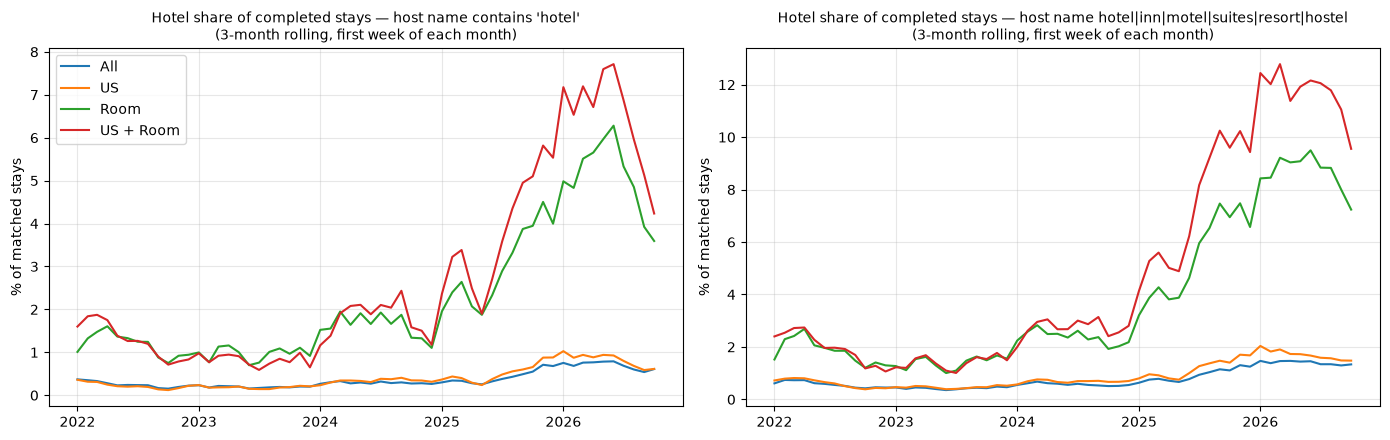

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, (t, label) in zip(axes, [(word, "host name contains 'hotel'"), (kw, "host name hotel|inn|motel|suites|resort|hostel")]):
    for cut in CUTS:
        ax.plot(t.index, t[(cut, "% stays")].rolling(3, min_periods=1).mean(), label=cut)
    ax.set_title(f"Hotel share of completed stays — {label}\n(3-month rolling, first week of each month)", fontsize=10)
    ax.set_ylabel("% of matched stays")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

In [35]:
# Yearly view (sum of the monthly weeks) to smooth the small hotel counts.
stays["year"] = stays.month.dt.year
yr = {}
for cut, mask in CUTS.items():
    d = stays[mask]
    g = d.groupby("year")
    yr[(cut, "stays")] = g.size()
    for flag in ["hotel_word", "hotel_kw"]:
        yr[(cut, f"% {flag}")] = 100 * d[d[flag]].groupby("year").size() / g.size()
        yr[(cut, f"% value {flag}")] = 100 * d[d[flag]].groupby("year").usd_value.sum() / g.usd_value.sum()
yearly = pd.DataFrame(yr).round(2)
yearly.columns = pd.MultiIndex.from_tuples(yearly.columns)
yearly

All                                                                 US                                                               Room                                                             US + Room  \
       stays % hotel_word % value hotel_word % hotel_kw % value hotel_kw  stays % hotel_word % value hotel_word % hotel_kw % value hotel_kw  stays % hotel_word % value hotel_word % hotel_kw % value hotel_kw     stays   
year                                                                                                                                                                                                                       
2022   90309         0.22               0.12       0.52             0.44  58600         0.19               0.10       0.54             0.45  11781         1.12               1.27       1.71             1.84      7568   
2023  120784         0.19               0.11       0.43             0.35  74699         0.18               0.10       0.47             0.36  13722         0.97               0.98       1.43             1.41      8104   
2024  121974         0.29               0.13       0.57             0.35  73851         0.35               0.14       0.70             0.41  12405         1.68               1.68       2.43             2.54      7248   
2025  105117         0.45               0.19       0.98             0.57  60599         0.57               0.22       1.29             0.69  11423         3.25               3.40       5.86             6.39      6617   
2026   76824         0.69               0.31       1.40             0.77  48841         0.78               0.33       1.66             0.84   8018         5.08               5.91       8.76             9.87      4946   

                                                                  
     % hotel_word % value hotel_word % hotel_kw % value hotel_kw  
year                                                              
2022         1.12               1.18       1.76             1.84  
2023         0.80               0.91       1.44             1.38  
2024         1.90               1.69       2.88             2.70  
2025         4.29               3.92       8.24             7.88  
2026         6.35               6.49      11.71            11.72

In [36]:
# Match quality by week: review emails, stays matched, share of hotel-named reviews matched, gap to checkout.
rq = reviews.groupby("week").agg(review_emails=("mailbox_id", "size"), hotel_word_emails=("hotel_word", "sum"))
sq = stays.groupby("month").agg(matched_stays=("message_id", "size"), matched_review_emails=("review_emails", "sum"),
                                 hotel_word_stays=("hotel_word", "sum"), median_gap_days=("gap_days", "median"))
mq = rq.join(sq)
mq["pct_review_emails_matched"] = (100 * mq.matched_review_emails / mq.review_emails).round(1)
mq

,review_emails,hotel_word_emails,matched_stays,matched_review_emails,hotel_word_stays,median_gap_days,pct_review_emails_matched
week,,,,,,,
2022-01-01,14326,27,821,885,3,0.0,6.2
2022-02-01,10862,22,3675,4183,12,0.0,38.5
2022-03-01,14615,26,6502,7015,19,0.0,48.0
2022-04-01,15305,18,6799,7311,15,0.0,47.8
2022-05-01,16220,17,7627,8013,14,0.0,49.4
2022-06-01,18027,30,8688,9153,28,0.0,50.8
2022-07-01,24023,31,10688,13186,22,0.0,54.9
2022-08-01,26001,25,11429,14940,19,0.0,57.5
2022-09-01,26766,17,10756,15463,13,0.0,57.8


## C5. Findings (run 2026-10-15)

**Coverage.**
- 1.22M review-request emails over 58 weeks matched to 515k stays.
- 57–65% of review emails match an Order Confirmation in every week from Mar 2022. The rest are mostly host-side reviews and stays booked before the mailbox joined the panel.
- Jan–Feb 2022 are a ramp (6% and 38% matched) because Order Confirmations before ~late 2021 are thin. Treat them as unreliable.
- Median gap from checkout to review is 0 days throughout.

**Hotel share of completed stays, yearly** (sum of the first week of each month; 2026 = Jan–Oct):

| Year | All, word | All, kw | US, word | US, kw | Room, word | Room, kw | US+Room, word | US+Room, kw |
|---|---|---|---|---|---|---|---|---|
| 2022 | 0.22% | 0.52% | 0.19% | 0.54% | 1.1% | 1.7% | 1.1% | 1.8% |
| 2023 | 0.19% | 0.43% | 0.18% | 0.47% | 1.0% | 1.4% | 0.8% | 1.4% |
| 2024 | 0.29% | 0.57% | 0.35% | 0.70% | 1.7% | 2.4% | 1.9% | 2.9% |
| 2025 | 0.45% | 0.98% | 0.57% | 1.29% | 3.3% | 5.9% | 4.3% | 8.2% |
| 2026 | 0.69% | 1.40% | 0.78% | 1.66% | 5.1% | 8.8% | 6.4% | 11.7% |

**What the series shows**
- **Clear growth from 2024, steepest in mid-2025.** The hotel-host share of all stays is roughly 3x 2022–23 levels (word: ~0.2% → ~0.7%; kw: ~0.5% → ~1.4%). Monthly, the step-up starts around Jun–Jul 2025, and the series peaks around Jan and Apr 2026.
- **US runs slightly above All** from 2024, by about 0.1–0.4pp on kw. The trend is the same.
- **"Room" is where the signal concentrates.**
  - Hotel hosts' share of "Room" stays rose from ~1% (word) / ~1.5% (kw) in 2022–23 to 5% / 9% in 2026.
  - US + Room reaches 6% / 12%.
  - "Room" is only ~10% of stays, so the Room cut is ~7x more sensitive. It is also noisier: 20–100 hotel stays a month.
- **Nights and value.**
  - Across all stays, hotel % nights and % value sit below % stays, because hotel stays are shorter and cheaper than the average whole-home stay.
  - Within "Room", % value is at or above % stays, because hotels are pricier than private rooms.
- **Not the same as `accommodation_type = 'Hotel room'`.** That field was 0.2–0.6% of Order Confirmations and flat or down (B3). The hotel-host series is a similar order of magnitude for All but rising, and C2 showed the two capture different stays.

**Caveats**
- **Lower bound.** Only hosts with a hotel word in their name are counted. `kw` also includes some look-alikes (e.g. host-run "suites"), so the truth for named hotels is between `word` and `kw`, plus unnamed hotels on top.
- **Possible understatement from Jul 2026.**
  - Hotel-word stays per hotel-word review email were 0.7–0.85 through 2025 but 0.45–0.57 in Jul–Oct 2026.
  - The 0–14 day window did not close this gap. So the Sep 2026 drop seen in C2 is not just reminders falling outside the window.
  - This lines up with the Room-cut dip from Jul 2026 (word ~6–7% → 3–4%) while All kw stays ~1.3–1.4%.
  - Cause still open. It could be more hotel reviews arriving without a matchable Order Confirmation, or hotel stays shifting out of "Room".
- **Timing and sample.**
  - The measure is completed stays at checkout, not bookings, so it lags bookings by the lead time.
  - Each month is a single week's sample.
  - Monthly hotel counts are small (10–150), so read the yearly or rolling series.